## Finetuning CNN model with and without SSL

**Important: move project into MyDrive before running**
Otherwise, you will encounter issues with mouting the drive.


In [ ]:
import os
import csv
from pathlib import Path
from typing import List, Dict, Tuple, Optional
from google.colab import drive

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
import torch.multiprocessing


from PIL import Image as PILImage
from IPython.display import display, HTML

from transformers import AutoImageProcessor, AutoModelForImageClassification, BertTokenizer, BertModel
from torch.optim import AdamW

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

import pandas as pd
import numpy as np
import random
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

The preprocessing steps for social media captions, specifically leveraging BERT, involve the following:

1.  **Text Extraction and Storage (`load_and_preprocess_social_media_metadata` function and `SOCIAL_TEXT_LOOKUP`)**:
    *   **Description**: In the `load_and_preprocess_social_media_metadata` function (cell `e571e8b5`), the `post_text` or `caption_text` from the social media metadata CSV files is extracted. Each image's text content is then stored in a dictionary called `SOCIAL_TEXT_LOOKUP`, where the key is the image path and the value is the associated text string.
    *   **Why it helps**: This step systematically collects the raw text data associated with each image, making it accessible for subsequent natural language processing. It ensures that the model has access to the textual context of each image.

2.  **Tokenization (`BertTokenizer` in `collate_for_final_combined_model`)**:
    *   **Description**: Within the `collate_for_final_combined_model` function (cell `0ff2f085`), the raw text strings from `SOCIAL_TEXT_LOOKUP` are processed using `BertTokenizer.from_pretrained('bert-base-multilingual-cased')`. This tokenizer converts the human-readable text into numerical tokens (input IDs) that the BERT model can understand. It also generates an `attention_mask` to distinguish real tokens from padding tokens.
        *   `padding=True`: Ensures all text sequences in a batch have the same length by adding padding tokens, which is necessary for batch processing by neural networks.
        *   `truncation=True`: If a text sequence is longer than the maximum length BERT can handle, it is truncated.
        *   `max_length=128`: Sets the maximum sequence length to 128 tokens. This balances capturing sufficient context with computational efficiency.
    *   **Why it helps**: BERT is a Transformer-based model that operates on numerical token IDs. Tokenization converts diverse human language into a standardized numerical format. Padding and truncation ensure efficient batch processing by standardizing input dimensions, while `max_length` helps manage memory and computation.

3.  **BERT Embedding Generation (`bert_model` in `FinalCombinedModel`)**:
    *   **Description**: The tokenized inputs (`input_ids` and `attention_mask`) are fed into the `bert_model` (cell `71e9bcda`). This pre-trained BERT model then generates context-aware embeddings for the text. The `pooler_output` from BERT, which typically represents a high-level, aggregate contextualized embedding for the entire input sequence (often derived from the `[CLS]` token), is used as the text feature.
    *   **Why it helps**: BERT is a powerful pre-trained language model that has learned rich representations of language from vast amounts of text data. By using BERT, the model can capture complex semantic relationships, syntax, and context within the captions. This provides a deep understanding of the textual content, which is crucial for distinguishing between AI-generated and human-generated content where subtle linguistic cues might be important.

4.  **Freezing BERT Parameters (`bert_model` initialization in cell `71e9bcda`)**:
    *   **Description**: The parameters (weights) of the `bert_model` are explicitly frozen using `for param in bert_model.parameters(): param.requires_grad = False` (cell `71e9bcda`). This means that during the training of our `FinalCombinedModel`, BERT's internal weights are not updated.
    *   **Why it helps**: Freezing BERT is a form of transfer learning. It allows the model to leverage BERT's extensive pre-trained linguistic knowledge without requiring massive amounts of text-specific data for fine-tuning BERT's weights. This prevents overfitting on a relatively smaller dataset, significantly speeds up training, and makes the overall training process more stable, as BERT's well-learned representations remain intact.

5.  **Text Projection (`text_projection` layer in `FinalCombinedModel`)**:
    *   **Description**: The `pooler_output` from BERT is passed through a linear layer called `text_projection` (`nn.Linear(self.bert_output_size, self.cnn_feature_output_size // 2)`). This layer transforms BERT's output dimension (e.g., 768 for `bert-base`) to a potentially lower and more compatible dimension (e.g., 384 for half of the CNN feature size) before concatenation with other features.
    *   **Why it helps**: This projection layer serves to adapt the dimensionality of the BERT embeddings to better integrate with the features from the CNN and other metadata MLPs. It can help reduce the complexity of the combined feature vector, potentially making the final classification layer more efficient and robust. It acts as a bridge, ensuring that the textual features are aligned and scaled appropriately before being combined with visual and numerical metadata features.

We create all of the global variables. These include paths to all  the necessary folders, as well as batch size, learning rate, etc

In [ ]:
ROOT = Path("/content/drive/MyDrive/Project 1-1/Dataset")
LABELED_DIR = ROOT / "Images" / "Labeled"
UNLABELED_DIR = ROOT / "Images" / "Unlabeled"
PSEUDO_CSV = ROOT / "Images" / "pseudo_labels.csv"
TEST_SET_DIR = ROOT / "Images" / "Test"

MODEL_IDENTIFIER = "Ateeqq/ai-vs-human-image-detector"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# hyperparameter values chosen empirically based on performance on validation set
BATCH_SIZE = 16
FINETUNE_EPOCHS = 5
LR = 5e-6
WEIGHT_DECAY = 1e-4

MODEL_SAVE_PATH = ROOT / "finetuned_cnn_model.pth"

Also, instantiate all of the hyper parameters for the semi supervised learning loop.

In [ ]:
AI_CLASS_WEIGHT = 2 # the higher this number, the higher the cost of misclassifying AI as not AI
LABELED_SAMPLE_WEIGHT = 1.0
PSEUDO_SAMPLE_WEIGHT = 0.3 # to account for the fact that pseudo labels might not be aligned with the ground truth

PSEUDO_THRESHOLD = 0.98 # minimum confidence the model needs to have to assign a predicted label as pseudo label


In [ ]:
drive.mount('/content/drive')
processor = AutoImageProcessor.from_pretrained(MODEL_IDENTIFIER)
model = AutoModelForImageClassification.from_pretrained(MODEL_IDENTIFIER).to(DEVICE)

Mounted at /content/drive


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/372M [00:00<?, ?B/s]

Next, in order to load the (changing) dataset most effectively, let us create a dataset class.

In [ ]:
class SimpleImageDataset(Dataset):
    def __init__(self, items: List[Tuple[Path, int, float]]):
        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, label, sweight = self.items[idx]
        img = PILImage.open(path).convert("RGB")
        return img, (label if label is not None else -1), str(path), float(sweight)

The class above returns PIL images (python image library), not tensors. Therefore, to prepare the images to be processed, we need one more method to turn them into a format in which they can be processed.

In [ ]:

def collate_for_processor(batch):
    images = [b[0] for b in batch]
    labels = torch.tensor([b[1] for b in batch], dtype=torch.long)
    paths = [b[2] for b in batch]
    sample_weights = torch.tensor([b[3] for b in batch], dtype=torch.float)

    # processor will stack and return tensors
    inputs = processor(images=images, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    labels = labels.to(DEVICE)
    sample_weights = sample_weights.to(DEVICE)
    return inputs, labels, paths, sample_weights


The function below will create the labeled instances of AI and not AI from the respective AI and not AI folders.


In [ ]:
def build_labeled_items(labeled_root: Path) -> Tuple[List[Tuple[Path,int,float]], Dict[str, int]]:
    dataset = ImageFolder(str(labeled_root))  # uses folder names for classes

    target_class_to_idx = {'Not_AI': 0, 'AI': 1} # defines AI as the positie class

    imagefolder_class_to_idx = dataset.class_to_idx

    # Create a remapping dictionary from ImageFolder's indices to our target indices
    remapping = {imagefolder_class_to_idx[cls_name]: target_class_to_idx[cls_name]
                 for cls_name in target_class_to_idx if cls_name in imagefolder_class_to_idx}

    items = []
    for path, cls_original in dataset.samples:
        remapped_cls = remapping[cls_original]
        items.append((Path(path), int(remapped_cls), LABELED_SAMPLE_WEIGHT))

    return items, target_class_to_idx

def build_split_labeled_items(labeled_root: Path, test_set_dir: Path, val_split_ratio: float) -> Tuple[List[Tuple[Path,int,float]], List[Tuple[Path,int,float]], List[Tuple[Path,int,float]], Dict[str, int]]:
    # This method first creates the labeled training instances, then splits them into training and validation. It also loads the test set.

    # load labeled instances that will be used for training and validation
    train_val_pool_items, class_to_idx = build_labeled_items(labeled_root)

    # load test set from its own directory
    labeled_test_items, _ = build_labeled_items(test_set_dir)

    # Stratify by class to maintain distribution.
    labeled_train_items, labeled_val_items = train_test_split(
        train_val_pool_items,
        test_size=val_split_ratio,
        random_state=42, # Using a fixed random state for reproducibility and ensure performance change comes from hyperparameter change and not luckier train/validation split
        stratify=[item[1] for item in train_val_pool_items]
    )

    print(f"Split Labeled Data: Train={len(labeled_train_items)}, Validation={len(labeled_val_items)}, Test={len(labeled_test_items)}")
    return labeled_train_items, labeled_val_items, labeled_test_items, class_to_idx

In [ ]:
@torch.no_grad()
def predict_dataset(model, processor, dataloader) -> List[Dict]:
    # Runs batched inference on dataloader

    model.eval()
    out = []
    for inputs, labels, paths, sample_weights in dataloader:
        outputs = model(**inputs)
        logits = outputs.logits
        probs = torch.softmax(logits, dim=-1).cpu()
        pred_idx = logits.argmax(-1).cpu()
        batch_size = logits.shape[0]
        for i in range(batch_size):
            pi = int(pred_idx[i].item()) # predicts instance
            conf = float(probs[i, pi].item()) # calculates confidence
            out.append({
                "image_path": paths[i],
                "pred_idx": pi,
                "confidence": conf
            })
    return out


The method below finetunes the model based on the currently available labeled data. It uses weighted cross entropy loss, to account for AI/Not AI and labeled vs pseudo labeled data.

In [ ]:
def finetune_model(model, train_items: List[Tuple[Path,int,float]],
                   val_loader: DataLoader = None,
                   class_weight: float = AI_CLASS_WEIGHT,
                   epochs: int = FINETUNE_EPOCHS,
                   batch_size: int = BATCH_SIZE,
                   lr: float = LR,
                   patience: int = 2):

    ds = SimpleImageDataset(train_items)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, collate_fn=collate_for_processor, num_workers=0)

    class_weights = torch.tensor([1.0, float(class_weight)], dtype=torch.float).to(DEVICE)
    criterion = nn.CrossEntropyLoss(reduction='none', weight=class_weights)

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)

    # we also need to make sure we do not overfit. We therefore store the best validation loss and the best model state, to be able to rollback
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_state = None

    # first, finetune the model on the labeled data
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        n_samples = 0
        for inputs, labels, paths, sample_weights in loader:
            outputs = model(**inputs)
            logits = outputs.logits
            losses = criterion(logits, labels)
            weighted_losses = losses * sample_weights
            loss = weighted_losses.mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += float(loss.item()) * logits.shape[0]
            n_samples += logits.shape[0]

        avg_train_loss = epoch_loss / max(1, n_samples)
        print(f"[finetune] epoch {epoch+1}/{epochs} avg_train_loss={avg_train_loss:.5f}")

        # Validation step
        if val_loader:
            model.eval()
            val_loss = 0.0
            val_n_samples = 0
            with torch.no_grad():
                for inputs, labels, paths, sample_weights in val_loader:
                    outputs = model(**inputs)
                    logits = outputs.logits
                    losses = criterion(logits, labels)
                    weighted_losses = losses * sample_weights
                    val_loss += float(weighted_losses.mean().item()) * logits.shape[0]
                    val_n_samples += logits.shape[0]
            avg_val_loss = val_loss / max(1, val_n_samples)
            print(f"[finetune] Validation Loss: {avg_val_loss:.5f}")

            # Early stopping check to avoid overfitting
            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                epochs_no_improve = 0
                best_model_state = model.state_dict()
            else:
                epochs_no_improve += 1
                print(f"[finetune] No improvement in validation loss for {epochs_no_improve} epochs.")

            if epochs_no_improve >= patience:
                print(f"[finetune] Early stopping triggered after {patience} epochs without improvement.")
                break

    if best_model_state:
        model.load_state_dict(best_model_state)
        print("[finetune] Loaded best model state based on validation loss.")
    return model

We also need a way to store pseudolabels, as we will not want to keep moving them from folder to folder. For this, we save the pseudo labels in a csv file. We therefore create a method that creates the csv file, and one that retrieves the pseudo labels from it

In [ ]:
def load_pseudo_csv(csv_path: Path) -> List[Tuple[Path,int,float,float]]:
    if not csv_path.exists():
        return []
    rows = []
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for r in reader:
            p = Path(r["image_path"])
            if not p.exists():
                continue
            lbl = int(r["label"])
            conf = float(r.get("confidence", 0.0))
            rows.append((p, lbl, PSEUDO_SAMPLE_WEIGHT, conf))
    return rows

def write_pseudo_csv(rows: List[Dict], csv_path: Path):
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["image_path","label","confidence"])
        writer.writeheader()
        for r in rows:
            writer.writerow({
                "image_path": str(r["image_path"]),
                "label": int(r["label"]),
                "confidence": float(r["confidence"])
            })

  The method below computes and prints the class balance.


In [ ]:
def get_class_balance(items: List[Tuple[Path, int, float]], description: str, idx_to_class: Dict[int, str]):
    if not items:
        print(f"No items found for {description}.")
        return

    labels = [item[1] for item in items]
    label_counts = pd.Series(labels).value_counts().sort_index()

    print(f"\n--- Class Balance for {description} ---")
    class_balance_data = []
    total_samples = len(labels)
    for label_idx, count in label_counts.items():
        class_name = idx_to_class.get(label_idx, f"Unknown ({label_idx})")
        percentage = (count / total_samples) * 100
        class_balance_data.append([class_name, count, f"{percentage:.2f}%"])

    class_balance_df = pd.DataFrame(class_balance_data, columns=['Class', 'Count', 'Percentage'])
    display(class_balance_df)
    print(f"Total samples: {total_samples}")

if 'class_to_idx' not in globals():
    _, class_to_idx = build_labeled_items(LABELED_DIR)
    idx_to_class = {v: k for k, v in class_to_idx.items()}

# Get the labeled data splits again (from the original directories)
labeled_train_items, labeled_val_items, labeled_test_items, _ = \
    build_split_labeled_items(LABELED_DIR, TEST_SET_DIR, 0.2) # Using the same split ratio as in ssl_loop

# Compute class balance for labeled datasets
get_class_balance(labeled_train_items, "Labeled Training Data", idx_to_class)
get_class_balance(labeled_val_items, "Labeled Validation Data", idx_to_class)
get_class_balance(labeled_test_items, "Labeled Test Data", idx_to_class)

pseudo_rows = load_pseudo_csv(PSEUDO_CSV)
pseudo_labeled_items = [(p, lbl, conf) for (p, lbl, _, conf) in pseudo_rows]

get_class_balance(pseudo_labeled_items, "Pseudo-Labeled Data (from SSL Iteration)", idx_to_class)


Split Labeled Data: Train=180, Validation=46, Test=50

--- Class Balance for Labeled Training Data ---


,Class,Count,Percentage
0,Not_AI,136,75.56%
1,AI,44,24.44%


Total samples: 180

--- Class Balance for Labeled Validation Data ---


,Class,Count,Percentage
0,Not_AI,35,76.09%
1,AI,11,23.91%


Total samples: 46

--- Class Balance for Labeled Test Data ---


,Class,Count,Percentage
0,Not_AI,30,60.00%
1,AI,20,40.00%


Total samples: 50

--- Class Balance for Pseudo-Labeled Data (from SSL Iteration) ---


,Class,Count,Percentage
0,Not_AI,678,64.76%
1,AI,369,35.24%


Total samples: 1047


We also want to make sure that after the semi supervised learning loop, we are able to use the enlarged dataset also for the combined models.

In [ ]:
def export_final_dataset(labeled_items: List[Tuple[Path,int,float]], pseudo_csv_path: Path, output_csv_path: str, class_to_idx: Dict[str, int]):
    # Combines labeled and pseudo-labeled data into a single CSV file.

    print(f"Exporting combined dataset to {output_csv_path}...")

    idx_to_class = {v: k for k, v in class_to_idx.items()}

    pseudo_rows = load_pseudo_csv(pseudo_csv_path)
    final_pseudo_items = [(p, lbl, PSEUDO_SAMPLE_WEIGHT) for (p, lbl, _,) in [(r[0], r[1], r[2]) for r in pseudo_rows]]

    all_data_for_export = []
    for path, label, _ in labeled_items:
        all_data_for_export.append({"image_path": str(path), "label": label})

    for path, label, _ in final_pseudo_items:
        all_data_for_export.append({"image_path": str(path), "label": label})

    df = pd.DataFrame(all_data_for_export)
    df["label"] = df["label"].map(idx_to_class)

    output_csv_path_obj = Path(output_csv_path)
    output_csv_path_obj.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(output_csv_path_obj, index=False)
    print(f"Successfully exported {len(df)} samples.")

Now that all the pieces, we need to write the main ssl loop, and lastly a function that calls it.

In [ ]:
def ssl_loop(iterations: int = 3,
             pseudo_threshold: float = PSEUDO_THRESHOLD,
             labeled_val_split_ratio: float = 0.2,
             early_stopping_patience: int = 2,
             model_save_path: Path = MODEL_SAVE_PATH):

    # Use the modified build_split_labeled_items to get the splits
    labeled_train_items, labeled_val_items, labeled_test_items, class_to_idx = \
        build_split_labeled_items(LABELED_DIR, TEST_SET_DIR, labeled_val_split_ratio)

    print("Detected class_to_idx:", class_to_idx)

    # Invert class_to_idx for evaluation printing
    idx_to_class = {v: k for k, v in class_to_idx.items()}

    # Create DataLoaders for evaluation throughout the loop
    labeled_train_ds_eval = SimpleImageDataset(labeled_train_items)
    labeled_train_loader_eval = DataLoader(labeled_train_ds_eval, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_for_processor, num_workers=0)

    labeled_val_ds_eval = SimpleImageDataset(labeled_val_items)
    labeled_val_loader_eval = DataLoader(labeled_val_ds_eval, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_for_processor, num_workers=0)

    labeled_test_ds_eval = SimpleImageDataset(labeled_test_items)
    labeled_test_loader_eval = DataLoader(labeled_test_ds_eval, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_for_processor, num_workers=0)

    for it in range(iterations):
        print(f"\n=== SSL ITER {it+1}/{iterations} ===")

        # load previous pseudo labels
        pseudo_rows = load_pseudo_csv(PSEUDO_CSV)
        # convert to train_items: labeled (high weight) + pseudolabeled (lower sample weight)
        pseudo_train_items = [(p, lbl, PSEUDO_SAMPLE_WEIGHT) for (p,lbl,_,) in [(r[0], r[1], r[2]) for r in pseudo_rows]]
        combined_train = labeled_train_items + pseudo_train_items

        # Filter out any non-existent paths from combined_train
        combined_train = [item for item in combined_train if item[0].exists()]

        print(f"Training on {len(combined_train)} samples ({len(labeled_train_items)} labeled train + {len(pseudo_train_items)} pseudo)")

        # finetune
        finetune_model(model, combined_train, val_loader=labeled_val_loader_eval, class_weight=AI_CLASS_WEIGHT, epochs=FINETUNE_EPOCHS, patience=early_stopping_patience)

        # Evaluate on training and validation data after finetuning in this iteration
        evaluate_model_metrics(model, labeled_train_loader_eval, idx_to_class, phase=f"Labeled Training Data Evaluation after Iter {it+1}")
        evaluate_model_metrics(model, labeled_val_loader_eval, idx_to_class, phase=f"Labeled Validation Data Evaluation after Iter {it+1}")

        # Now predict on entire unlabeled set
        unlabeled_paths = [p for p in sorted(UNLABELED_DIR.glob("*")) if p.is_file()]
        unlabeled_items = [(p, None, 1.0) for p in unlabeled_paths]
        unl_ds = SimpleImageDataset(unlabeled_items)
        unl_loader = DataLoader(unl_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_for_processor, num_workers=0)

        preds = predict_dataset(model, processor, unl_loader)

        accepted = []
        for p in preds:
            if p["confidence"] >= pseudo_threshold:
                accepted.append({"image_path": p["image_path"], "label": p["pred_idx"], "confidence": p["confidence"]})

        print(f"Accepted {len(accepted)} pseudo labels out of {len(preds)} unlabeled images (threshold={pseudo_threshold})")
        write_pseudo_csv(accepted, PSEUDO_CSV)

    print("SSL loop finished.")

    # Final Training and Evaluation
    print("\n=== FINAL TRAINING AND EVALUATION ===")
    final_pseudo_rows = load_pseudo_csv(PSEUDO_CSV)
    final_pseudo_train_items = [(p, lbl, PSEUDO_SAMPLE_WEIGHT) for (p,lbl,_,) in [(r[0], r[1], r[2]) for r in final_pseudo_rows]]
    final_combined_train = labeled_train_items + final_pseudo_train_items

    final_combined_train = [item for item in final_combined_train if item[0].exists()]

    print(f"Final training on {len(final_combined_train)} samples ({len(labeled_train_items)} labeled train + {len(final_pseudo_train_items)} pseudo)")
    finetune_model(model, final_combined_train, val_loader=labeled_val_loader_eval, class_weight=AI_CLASS_WEIGHT, epochs=FINETUNE_EPOCHS, patience=early_stopping_patience)

    # Final evaluation on all splits
    evaluate_model_metrics(model, labeled_train_loader_eval, idx_to_class, phase="Final Labeled Training Data Evaluation")
    evaluate_model_metrics(model, labeled_val_loader_eval, idx_to_class, phase="Final Labeled Validation Data Evaluation")
    evaluate_model_metrics(model, labeled_test_loader_eval, idx_to_class, phase="Final Labeled Test Data Evaluation")

    print("\nExporting final dataset...")
    all_labeled_for_export = labeled_train_items + labeled_val_items + labeled_test_items # Combine all labeled parts
    FINAL_COMBINED_DATASET_CSV = ROOT / "final_combined_dataset.csv"
    export_final_dataset(all_labeled_for_export, PSEUDO_CSV, str(FINAL_COMBINED_DATASET_CSV), class_to_idx) # Adjusted to accept items list

    model_save_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), model_save_path)
    print(f"Finetuned CNN model saved to {model_save_path}")

In [ ]:
def evaluate_model_metrics(model, dataloader, idx_to_class: dict, phase: str = "Evaluation"):

    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels, _, _ in dataloader:
            outputs = model(**inputs)
            logits = outputs.logits
            predictions = logits.argmax(dim=-1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    pos_label_idx = 1
    pos_label_name = idx_to_class.get(pos_label_idx, str(pos_label_idx))
    neg_label_name = idx_to_class.get(0, str(0))

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, pos_label=pos_label_idx, average='binary', zero_division=0)
    recall = recall_score(all_labels, all_preds, pos_label=pos_label_idx, average='binary', zero_division=0)
    f1 = f1_score(all_labels, all_preds, pos_label=pos_label_idx, average='binary', zero_division=0)

    cm = confusion_matrix(all_labels, all_preds, labels=[1, 0])

    print(f"--- {phase} Metrics ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision ({pos_label_name}): {precision:.4f}")
    print(f"Recall ({pos_label_name}): {recall:.4f}")
    print(f"F1-Score ({pos_label_name}): {f1:.4f}")
    print("\nConfusion Matrix:")
    print(f"{'':<10} {pos_label_name:<10} {neg_label_name:<10}")
    print(f"{'':-<10}-{'':-<10}-{'':-<10}")
    print(f"{pos_label_name:<10}| {cm[0, 0]:<10} {cm[0, 1]:<10}")
    print(f"{neg_label_name:<10}| {cm[1, 0]:<10} {cm[1, 1]:<10}")
    print("-----------------------")

We define a method to finetune only using labeled data.

In [ ]:
def finetune_only_labeled_test(epochs: int = 10):
    print("\n=== FINETUNING ON LABELED DATA ONLY ===")
    labeled_model = AutoModelForImageClassification.from_pretrained(MODEL_IDENTIFIER).to(DEVICE)

    labeled_train_items, labeled_val_items, labeled_test_items, class_to_idx = \
        build_split_labeled_items(LABELED_DIR, TEST_SET_DIR, 0.2)

    idx_to_class = {v: k for k, v in class_to_idx.items()}

    labeled_train_ds_eval = SimpleImageDataset(labeled_train_items)
    labeled_train_loader_eval = DataLoader(labeled_train_ds_eval, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_for_processor, num_workers=0)

    labeled_val_ds_eval = SimpleImageDataset(labeled_val_items)
    labeled_val_loader_eval = DataLoader(labeled_val_ds_eval, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_for_processor, num_workers=0)

    labeled_test_ds_eval = SimpleImageDataset(labeled_test_items)
    labeled_test_loader_eval = DataLoader(labeled_test_ds_eval, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_for_processor, num_workers=0)

    print(f"Starting finetuning on {len(labeled_train_items)} labeled samples for {epochs} epochs.")
    labeled_model = finetune_model(
        labeled_model,
        labeled_train_items,
        val_loader=labeled_val_loader_eval,
        class_weight=AI_CLASS_WEIGHT,
        epochs=epochs,
        batch_size=BATCH_SIZE,
        lr=LR,
        patience=2
    )

    print("\n--- Evaluation for Labeled-Only Finetuned Model ---")
    evaluate_model_metrics(labeled_model, labeled_train_loader_eval, idx_to_class, phase="Labeled-Only Training Data Evaluation")
    evaluate_model_metrics(labeled_model, labeled_val_loader_eval, idx_to_class, phase="Labeled-Only Validation Data Evaluation")
    evaluate_model_metrics(labeled_model, labeled_test_loader_eval, idx_to_class, phase="Labeled-Only Test Data Evaluation")

    print("Labeled-only finetuning test complete.")

finetune_only_labeled_test(epochs=10)

Below we call the semi-supervised learning loop

In [ ]:
torch.multiprocessing.set_start_method('spawn', force=True)
print("Labeled exists:", LABELED_DIR.exists(), "Unlabeled exists:", UNLABELED_DIR.exists(), "Test Set exists:", TEST_SET_DIR.exists())

ssl_loop(iterations=3, pseudo_threshold=PSEUDO_THRESHOLD, labeled_val_split_ratio=0.2, early_stopping_patience=2)

Labeled exists: True Unlabeled exists: True Test Set exists: True
Split Labeled Data: Train=180, Validation=46, Test=50
Detected class_to_idx: {'Not_AI': 0, 'AI': 1}

=== SSL ITER 1/3 ===
Training on 180 samples (180 labeled train + 0 pseudo)
[finetune] epoch 1/5 avg_train_loss=6.13350
[finetune] Validation Loss: 4.44008
[finetune] epoch 2/5 avg_train_loss=3.94171
[finetune] Validation Loss: 3.35306
[finetune] epoch 3/5 avg_train_loss=2.73692
[finetune] Validation Loss: 2.49650
[finetune] epoch 4/5 avg_train_loss=1.77953
[finetune] Validation Loss: 1.64193
[finetune] epoch 5/5 avg_train_loss=1.28633
[finetune] Validation Loss: 1.25852
[finetune] Loaded best model state based on validation loss.
--- Labeled Training Data Evaluation after Iter 1 Metrics ---
Accuracy: 0.8333
Precision (AI): 1.0000
Recall (AI): 0.3182
F1-Score (AI): 0.4828

Confusion Matrix:
           AI         Not_AI    
--------------------------------
AI        | 14         30        
Not_AI    | 0          136       

We can then observe the preditions our model makes, along with their (pseudo) labels

In [ ]:
_, class_to_idx = build_labeled_items(LABELED_DIR)
idx_to_class = {v: k for k, v in class_to_idx.items()}

FINAL_COMBINED_DATASET_CSV = ROOT / "final_combined_dataset.csv"

final_df = pd.read_csv(FINAL_COMBINED_DATASET_CSV)

pseudo_df = None
if PSEUDO_CSV.exists():
    pseudo_df = pd.read_csv(PSEUDO_CSV)
    pseudo_paths = set(pseudo_df['image_path'].tolist())
else:
    pseudo_paths = set()

print(f"Displaying {min(20, len(final_df))} sample images from the final combined dataset...")

sample_df = final_df.sample(min(20, len(final_df)), random_state=42).reset_index(drop=True)

# Prepare the model for inference
model.eval()

for index, row in sample_df.iterrows():
    image_path = Path(row['image_path'])
    assigned_label_str = row['label']

    label_source = "Pseudo-labeled" if str(image_path) in pseudo_paths else "Original Labeled"

    img = PILImage.open(image_path).convert("RGB")

    inputs = processor(images=img, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        pred_idx = logits.argmax(dim=-1).item()
        predicted_label_str = idx_to_class[pred_idx]

    display(HTML(f"<h3>Sample {index + 1}: {image_path.name}</h3>"))
    display(img)
    print(f"Source: {label_source}")
    print(f"Assigned Label: {assigned_label_str}")
    print(f"Model Prediction: {predicted_label_str}")
    print("\n" + "-"*50 + "\n")

Below we show how the finetuned model can be loaded to be used for inference.

In [ ]:
loaded_model = AutoModelForImageClassification.from_pretrained(MODEL_IDENTIFIER).to(DEVICE)
loaded_model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))

loaded_model.eval()

print(f"Model successfully loaded from {MODEL_SAVE_PATH} and set to evaluation mode.")

Model successfully loaded from /content/drive/MyDrive/Project 1-1/Dataset/finetuned_cnn_model.pth and set to evaluation mode.


Performing inference on 10 sample images from the pseudo-labeled dataset...


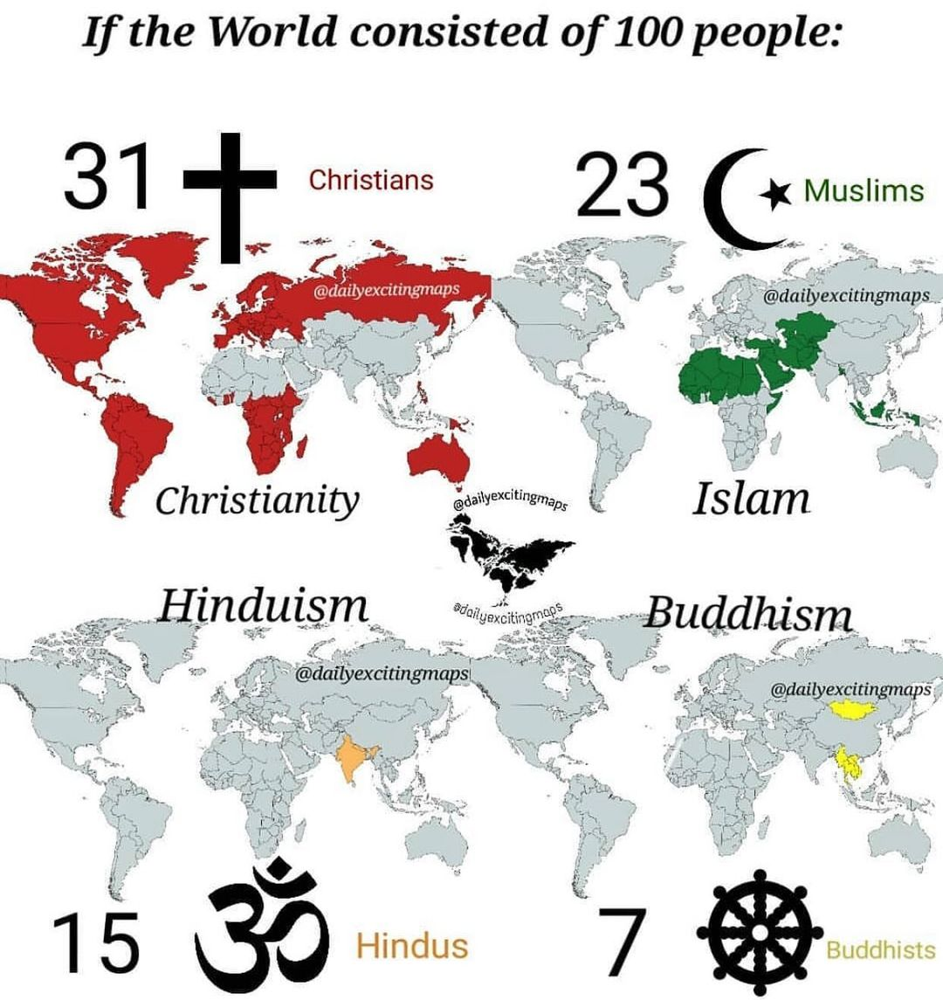

Pseudo-label (assigned during SSL): Not_AI (Confidence: 0.9930)
Model Prediction (after loading): Not_AI (Confidence: 0.9997)

--------------------------------------------------



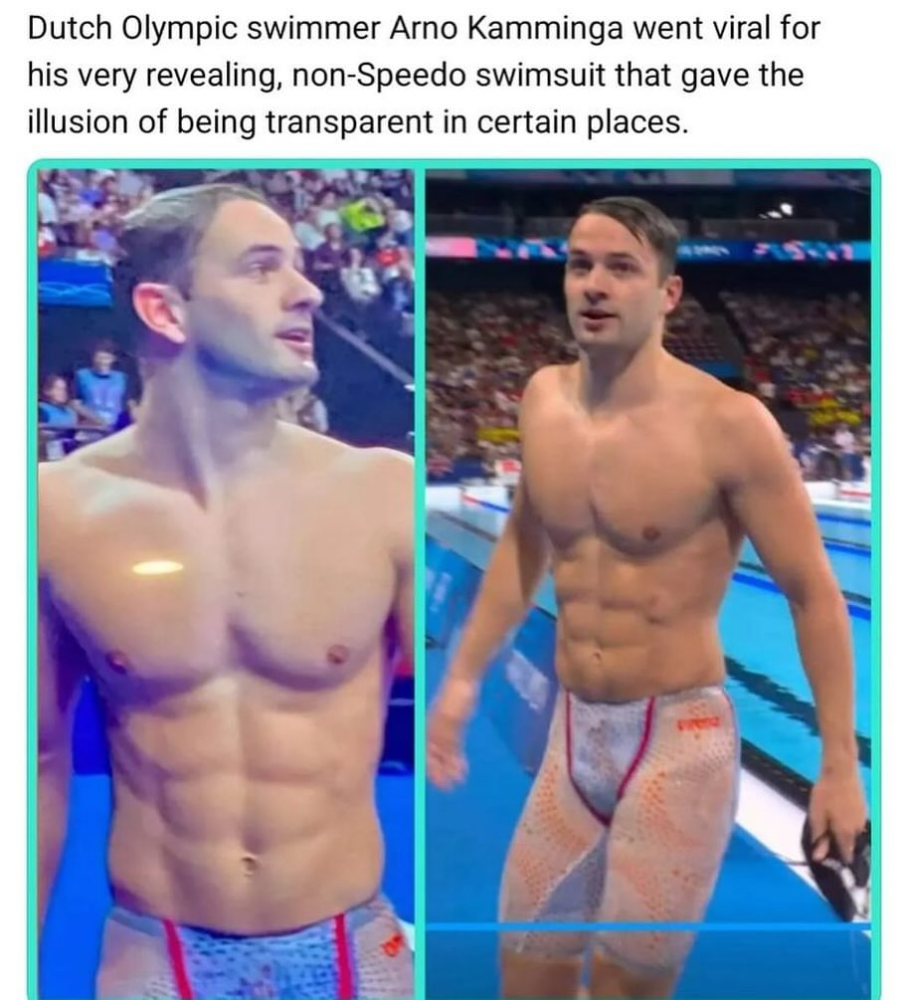

Pseudo-label (assigned during SSL): Not_AI (Confidence: 0.9999)
Model Prediction (after loading): Not_AI (Confidence: 1.0000)

--------------------------------------------------



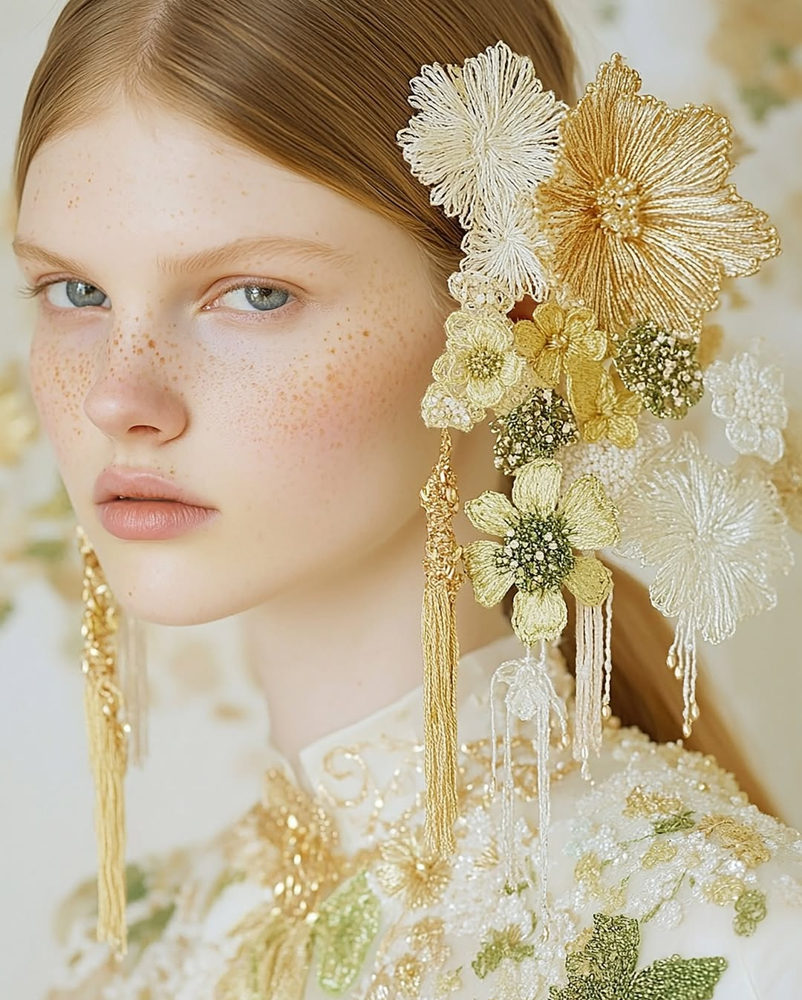

Pseudo-label (assigned during SSL): AI (Confidence: 1.0000)
Model Prediction (after loading): AI (Confidence: 0.9999)

--------------------------------------------------



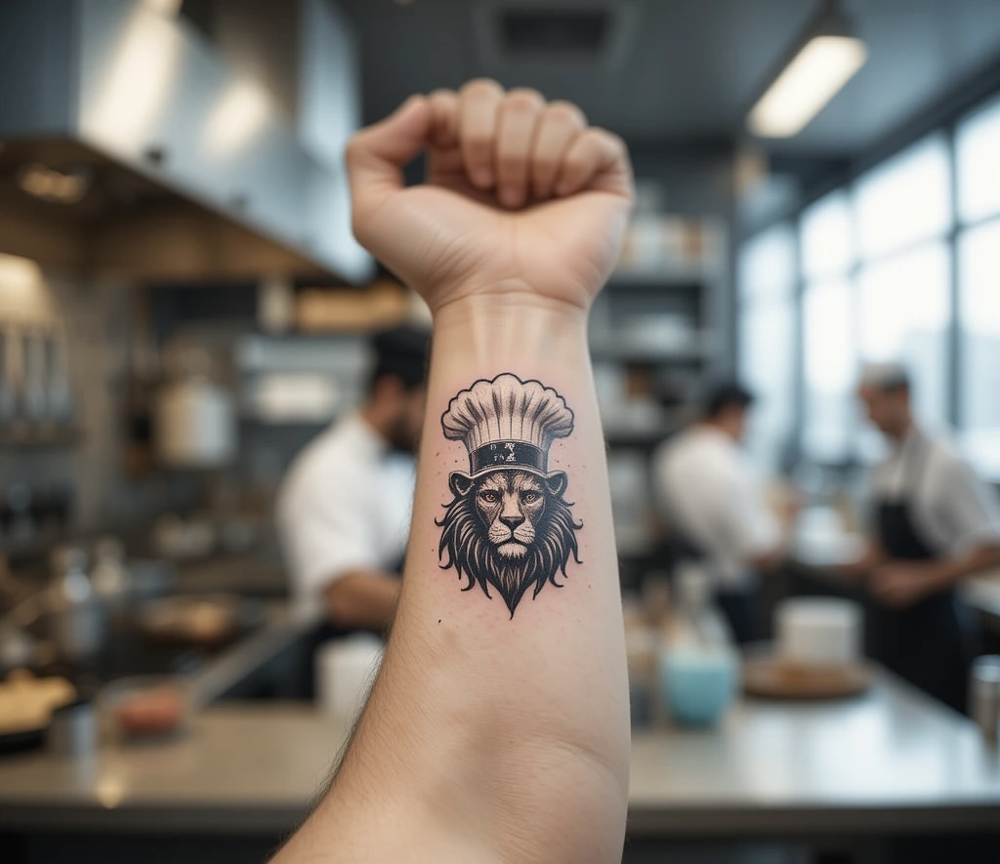

Pseudo-label (assigned during SSL): AI (Confidence: 1.0000)
Model Prediction (after loading): AI (Confidence: 0.9999)

--------------------------------------------------



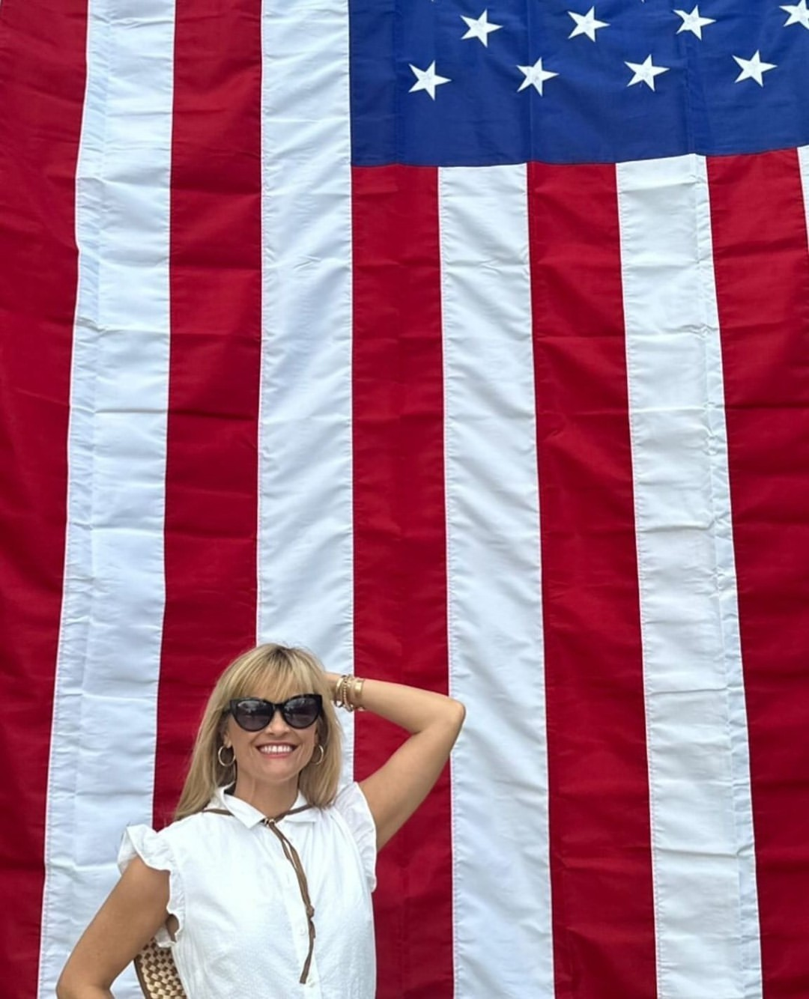

Pseudo-label (assigned during SSL): Not_AI (Confidence: 0.9963)
Model Prediction (after loading): Not_AI (Confidence: 0.9976)

--------------------------------------------------



In [ ]:
pseudo_df = pd.read_csv(PSEUDO_CSV)

print(f"Performing inference on {min(10, len(pseudo_df))} sample images from the pseudo-labeled dataset...")

sample_pseudo_df = pseudo_df.sample(min(5, len(pseudo_df)), random_state=42).reset_index(drop=True)
loaded_model.eval()

for index, row in sample_pseudo_df.iterrows():
    image_path = Path(row['image_path'])
    assigned_label_idx = row['label']
    assigned_confidence = row['confidence']
    assigned_label_str = idx_to_class[assigned_label_idx]

    img = PILImage.open(image_path).convert("RGB")

    # Perform inference with the loaded_model
    inputs = processor(images=img, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = loaded_model(**inputs)
        logits = outputs.logits
        probs = torch.softmax(logits, dim=-1)
        predicted_idx = logits.argmax(dim=-1).item()
        predicted_confidence = probs[0, predicted_idx].item()
        predicted_label_str = idx_to_class[predicted_idx]

    display(HTML(f"<h3>Sample {index + 1}: {image_path.name}</h3>"))
    display(img)
    print(f"Pseudo-label (assigned during SSL): {assigned_label_str} (Confidence: {assigned_confidence:.4f})")
    print(f"Model Prediction (after loading): {predicted_label_str} (Confidence: {predicted_confidence:.4f})")
    print("\n" + "-"*50 + "\n")

## COMBINED MODEL: CNN + EXIF METADATA

First we define a function to load and preprocess the available EXIF Metadata as well as match it with corresponding images

In [ ]:
AI_CLASS_WEIGHT = 3
FINETUNE_EPOCHS = 25
LR = 5e-5

In [ ]:
METADATA_ROOT = ROOT / "METADATA"

metadata_scaler = MinMaxScaler()
metadata_ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
metadata_feature_size = 0

def load_and_preprocess_metadata(metadata_filepaths: List[Path], labeled_dir: Path, unlabeled_dir: Optional[Path] = None, current_scaler: Optional[MinMaxScaler] = None, current_ohe: Optional[OneHotEncoder] = None) -> Tuple[Dict[str, np.ndarray], MinMaxScaler, OneHotEncoder, int]:
    all_dfs = []

    for filepath in metadata_filepaths:
        df = pd.read_csv(filepath)
        if 'A' in df.columns:
            df = df.rename(columns={'A': 'filename'})
        all_dfs.append(df)

    combined_df = pd.concat(all_dfs, ignore_index=True)

    # Define numerical and categorical columns
    numerical_cols_base = ['filesize', 'Megapixels', 'ImageSize', 'XResolution', 'YResolution']
    categorical_cols = ['YCbCrSubSampling', 'EncodingProcess', 'dqt_fingerprint']

    # Process 'ImageSize' from string to numerical area adn ratio
    numerical_cols_to_process = list(numerical_cols_base)
    if 'ImageSize' in combined_df.columns:
        combined_df['ImageSize_processed'] = combined_df['ImageSize'].apply(lambda x:
            int(x.split('x')[0]) * int(x.split('x')[1]) if isinstance(x, str) and 'x' in x else np.nan
        )
        combined_df['ImageRatio_processed'] = combined_df['ImageSize'].apply(lambda x:
            int(x.split('x')[0]) / int(x.split('x')[1]) if isinstance(x, str) and 'x' in x and int(x.split('x')[1]) != 0 else np.nan
        )

        if 'ImageSize' in numerical_cols_to_process:
            numerical_cols_to_process.remove('ImageSize')
        numerical_cols_to_process.append('ImageSize_processed')
        numerical_cols_to_process.append('ImageRatio_processed')
    else:
        numerical_cols_to_process = numerical_cols_base

    present_numerical_cols = [col for col in numerical_cols_to_process if col in combined_df.columns]
    present_categorical_cols = [col for col in categorical_cols if col in combined_df.columns]

    # Handle missing numerical values (mean imputation)
    for col in present_numerical_cols:
        combined_df[col] = pd.to_numeric(combined_df[col], errors='coerce')
        if combined_df[col].isnull().any():
            mean_val = combined_df[col].mean()
            combined_df[col] = combined_df[col].fillna(mean_val)

    # Handle missing categorical values (placeholder 'missing')
    for col in present_categorical_cols:
        combined_df[col] = combined_df[col].fillna('missing').astype(str)

    scaler = current_scaler if current_scaler else MinMaxScaler()
    ohe = current_ohe if current_ohe else OneHotEncoder(handle_unknown='ignore', sparse_output=False)

    # Scale numerical features
    if present_numerical_cols:
        if current_scaler:
            scaled_numerical_features = scaler.transform(combined_df[present_numerical_cols])
        else:
            scaled_numerical_features = scaler.fit_transform(combined_df[present_numerical_cols])
    else:
        scaled_numerical_features = np.array([]).reshape(len(combined_df), 0)

    # One-hot encode categorical features
    if present_categorical_cols:
        if current_ohe:
            ohe_features = ohe.transform(combined_df[present_categorical_cols])
        else:
            ohe_features = ohe.fit_transform(combined_df[present_categorical_cols])
    else:
        ohe_features = np.array([]).reshape(len(combined_df), 0)

    combined_processed_features = np.hstack((scaled_numerical_features, ohe_features))
    total_feature_size = combined_processed_features.shape[1]

    # Create the metadata lookup dictionary
    metadata_lookup = {}
    for idx, row in combined_df.iterrows():
        filename = row['filename']
        image_path = None

        labeled_path = labeled_dir / filename
        unlabeled_path = None
        if unlabeled_dir is not None:
            unlabeled_path = unlabeled_dir / filename

        if labeled_path.exists():
            image_path = labeled_path
        elif unlabeled_path is not None and unlabeled_path.exists():
            image_path = unlabeled_path
        else:
            for sub_dir in labeled_dir.iterdir():
                if sub_dir.is_dir():
                    labeled_sub_path = sub_dir / filename
                    if labeled_sub_path.exists():
                        image_path = labeled_sub_path
                        break
            if image_path is None:
                continue

        metadata_lookup[str(image_path)] = combined_processed_features[idx].astype(np.float32)

    return metadata_lookup, scaler, ohe, total_feature_size

metadata_files = [
    METADATA_ROOT / "exif_metadata_final.csv",
    METADATA_ROOT / "exif_metadata_ai_new.csv"
]
metadata_test_files = [
    METADATA_ROOT / "exif_metadata_test_ai_final.csv",
    METADATA_ROOT / "exif_metadata_test_notai_final.csv"
]

METADATA_LOOKUP, metadata_scaler, metadata_ohe, metadata_feature_size = load_and_preprocess_metadata(metadata_files, LABELED_DIR, UNLABELED_DIR)
METADATA_LOOKUP_TEST, _, _, _ = load_and_preprocess_metadata(metadata_test_files, TEST_SET_DIR, None, current_scaler=metadata_scaler, current_ohe=metadata_ohe)


print(f"Loaded and preprocessed metadata for {len(METADATA_LOOKUP)} images. Total feature size: {metadata_feature_size}")
print("First 5 entries of METADATA_LOOKUP:")
for i, (k, v) in enumerate(METADATA_LOOKUP.items()):
    if i >= 5: break
    print(f"  {k}: {v}")
print("\nFirst 5 entries of METADATA_LOOKUP_TEST:")
for i, (k, v) in enumerate(METADATA_LOOKUP_TEST.items()):
    if i >= 5: break
    print(f"  {k}: {v}")

Loaded and preprocessed metadata for 549 images. Total feature size: 53
First 5 entries of METADATA_LOOKUP:
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/davidgmcafee_3416696126743990946.jpg: [0.00911041 0.11332974 1.         1.         0.11420015 0.5050162
 1.         0.         0.         0.         1.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         1.
 0.         0.         0.         0.         0.        ]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/indypersian_lifestyle_3408463037860174183.jpg: [0.10044052 0.4603346  1.         1.         0.44449508 0.1106599
 1.         0.         0.         1.         0.         0.
 0.         0.        

In [ ]:
FINAL_COMBINED_DATASET_CSV = ROOT / "final_combined_dataset.csv"

if 'METADATA_LOOKUP' not in globals():
    METADATA_ROOT = ROOT / "METADATA"
    metadata_files = [
        METADATA_ROOT / "exif_metadata_final.csv",
        METADATA_ROOT / "exif_metadata_ai_new.csv"
    ]
    METADATA_LOOKUP = load_and_preprocess_metadata(metadata_files, LABELED_DIR, UNLABELED_DIR)
    print(f"METADATA_LOOKUP was not defined, re-initialized with {len(METADATA_LOOKUP)} entries.")

# Load the raw combined dataset (includes both labeled and pseudo-labeled)
raw_combined_df = pd.read_csv(FINAL_COMBINED_DATASET_CSV)

# Create a set of image paths for efficient metadata lookup
metadata_available_paths = set(METADATA_LOOKUP.keys())

# Filter the raw_combined_df to retain only images with corresponding metadata
filtered_df = raw_combined_df[raw_combined_df['image_path'].isin(metadata_available_paths)].copy()

print(f"Original combined dataset size: {len(raw_combined_df)} samples")
print(f"Filtered dataset size (with available metadata): {len(filtered_df)} samples")

# Create numerical_label column for stratification
if 'class_to_idx' not in globals():
    _, class_to_idx = build_labeled_items(LABELED_DIR)
filtered_df['numerical_label'] = filtered_df['label'].map(class_to_idx)

Original combined dataset size: 1323 samples
Filtered dataset size (with available metadata): 488 samples


Check Class Balance in Filtered Dataset (with Metadata and Pseudo-Labels)

In [ ]:
print('Class balance in the filtered dataset (images with metadata and pseudo-labels):')
class_counts = filtered_df['numerical_label'].value_counts()

idx_to_class = {v: k for k, v in class_to_idx.items()}
class_balance_df = pd.DataFrame({
    'Class': class_counts.index.map(idx_to_class),
    'Count': class_counts.values,
    'Percentage': (class_counts.values / len(filtered_df)) * 100
})

display(class_balance_df)

print(f"Total samples in filtered dataset: {len(filtered_df)}")

Class balance in the filtered dataset (images with metadata and pseudo-labels):


,Class,Count,Percentage
0,Not_AI,365,74.795082
1,AI,123,25.204918


Total samples in filtered dataset: 488


In [ ]:
class CombinedImageMetadataDataset(SimpleImageDataset):
    def __init__(self, items: List[Tuple[Path, int, float]], metadata_lookup: Dict[str, np.ndarray], metadata_feature_size: int):
        super().__init__(items)
        self.metadata_lookup = metadata_lookup
        self.metadata_vector_size = metadata_feature_size

    def __getitem__(self, idx):
        img, label, path_str, sweight = super().__getitem__(idx)

        metadata_vector = self.metadata_lookup.get(path_str)

        if metadata_vector is None:
            metadata_vector = np.zeros(self.metadata_vector_size, dtype=np.float32)

        return img, label, path_str, sweight, metadata_vector

def collate_for_combined_model(batch):
    images = [b[0] for b in batch]
    labels = torch.tensor([b[1] for b in batch], dtype=torch.long)
    paths = [b[2] for b in batch]
    sample_weights = torch.tensor([b[3] for b in batch], dtype=torch.float)
    metadata_vectors_np = [b[4] for b in batch]
    metadata_features = torch.tensor(np.stack(metadata_vectors_np), dtype=torch.float)

    inputs = processor(images=images, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    labels = labels.to(DEVICE)
    sample_weights = sample_weights.to(DEVICE)
    metadata_features = metadata_features.to(DEVICE)

    return inputs, labels, paths, sample_weights, metadata_features

In [ ]:
class CombinedModel(nn.Module):
    def __init__(self, cnn_model, metadata_feature_size: int, num_labels: int = 2, freeze_cnn_features: bool = True):
        super().__init__()

        # Extract CNN feature extractor from the pre-trained model
        self.cnn_feature_extractor = cnn_model.vision_model

        if hasattr(cnn_model, 'classifier') and hasattr(cnn_model.classifier, 'in_features'):
            self.cnn_feature_output_size = cnn_model.classifier.in_features
        elif hasattr(cnn_model, 'config') and hasattr(cnn_model.config, 'hidden_size'):
            self.cnn_feature_output_size = cnn_model.config.hidden_size
        else:
            raise ValueError("Could not determine CNN feature output size from cnn_model.")

        # Freeze CNN feature extractor parameters
        if freeze_cnn_features:
            for param in self.cnn_feature_extractor.parameters():
                param.requires_grad = False
            print(f"CNN feature extractor parameters frozen: {freeze_cnn_features}")

        # Define a Multi-Layer Perceptron (MLP) for metadata features
        self.metadata_mlp = nn.Sequential(
            nn.Linear(metadata_feature_size, self.cnn_feature_output_size // 2), # First hidden layer
            nn.ReLU(),
            nn.Linear(self.cnn_feature_output_size // 2, self.cnn_feature_output_size) # Output layer matching CNN feature size
        )

        # Define the final classification head
        # It takes the concatenated features (CNN_features + Metadata_features) as input.
        self.classifier = nn.Linear(self.cnn_feature_output_size + self.cnn_feature_output_size, num_labels)

    def forward(self, pixel_values, metadata_features):
        # Pass image pixel values through the CNN feature extractor
        cnn_outputs = self.cnn_feature_extractor(pixel_values=pixel_values, output_hidden_states=True, return_dict=True)

        # Prioritize extracting the CLS token from last_hidden_state
        if hasattr(cnn_outputs, 'last_hidden_state') and cnn_outputs.last_hidden_state is not None:
            image_features = cnn_outputs.last_hidden_state[:, 0, :]
        elif hasattr(cnn_outputs, 'pooled_output') and cnn_outputs.pooled_output is not None:
            image_features = cnn_outputs.pooled_output
        else:
            raise ValueError("Could not extract image features from CNN output. Neither last_hidden_state nor pooled_output available.")

        processed_metadata_features = self.metadata_mlp(metadata_features)

        combined_features = torch.cat((image_features, processed_metadata_features), dim=-1)

        logits = self.classifier(combined_features)

        return logits

combined_model = CombinedModel(cnn_model=model, metadata_feature_size= metadata_feature_size, num_labels=2, freeze_cnn_features=True)
combined_model.to(DEVICE)

print("CombinedModel instantiated and moved to device.")
print(combined_model)

CNN feature extractor parameters frozen: True
CombinedModel instantiated and moved to device.
CombinedModel(
  (cnn_feature_extractor): SiglipVisionTransformer(
    (embeddings): SiglipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), padding=valid)
      (position_embedding): Embedding(196, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (self_attn): SiglipAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (mlp): SiglipMLP(
          

In [ ]:
def finetune_combined_model(model: nn.Module,
                            train_items: List[Tuple[Path, int, float]],
                            val_loader: DataLoader = None,
                            class_weight: float = AI_CLASS_WEIGHT,
                            epochs: int = FINETUNE_EPOCHS,
                            batch_size: int = BATCH_SIZE,
                            lr: float = LR,
                            patience: int = 2):

    # prepare dataloader
    ds = CombinedImageMetadataDataset(train_items, METADATA_LOOKUP, metadata_feature_size)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, collate_fn=collate_for_combined_model, num_workers=0)

    # Class weighting: index 0=human, 1=ai
    class_weights = torch.tensor([1.0, float(class_weight)], dtype=torch.float).to(DEVICE)
    criterion = nn.CrossEntropyLoss(reduction='none', weight=class_weights)

    # Only optimize parameters that are not frozen
    optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=WEIGHT_DECAY)

    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        n_samples = 0
        for inputs, labels, paths, sample_weights, metadata_features in loader:
            pixel_values = inputs['pixel_values']

            outputs = model(pixel_values=pixel_values, metadata_features=metadata_features)
            logits = outputs

            losses = criterion(logits, labels)
            weighted_losses = losses * sample_weights
            loss = weighted_losses.mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += float(loss.item()) * logits.shape[0]
            n_samples += logits.shape[0]

        avg_train_loss = epoch_loss / max(1, n_samples)
        print(f"[finetune_combined] epoch {epoch+1}/{epochs} avg_train_loss={avg_train_loss:.5f}")

        # Validation step
        if val_loader:
            model.eval()
            val_loss = 0.0
            val_n_samples = 0
            with torch.no_grad():
                for inputs, labels, paths, sample_weights, metadata_features in val_loader:
                    pixel_values = inputs['pixel_values']
                    outputs = model(pixel_values=pixel_values, metadata_features=metadata_features)
                    logits = outputs
                    losses = criterion(logits, labels)
                    weighted_losses = losses * sample_weights
                    val_loss += float(weighted_losses.mean().item()) * logits.shape[0]
                    val_n_samples += logits.shape[0]
            avg_val_loss = val_loss / max(1, val_n_samples)
            print(f"[finetune_combined] Validation Loss: {avg_val_loss:.5f}")

            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                epochs_no_improve = 0
                best_model_state = model.state_dict()
            else:
                epochs_no_improve += 1
                print(f"[finetune_combined] No improvement in validation loss for {epochs_no_improve} epochs.")

            if epochs_no_improve >= patience:
                print(f"[finetune_combined] Early stopping triggered after {patience} epochs without improvement.")
                break

    if best_model_state:
        model.load_state_dict(best_model_state)
        print("[finetune_combined] Loaded best model state based on validation loss.")
    return model

@torch.no_grad()
def predict_combined_dataset(model: nn.Module, dataloader: DataLoader) -> List[Dict]:
    model.eval()
    out = []
    for inputs, labels, paths, sample_weights, metadata_features in dataloader:
        pixel_values = inputs['pixel_values']
        outputs = model(pixel_values=pixel_values, metadata_features=metadata_features)
        logits = outputs
        probs = torch.softmax(logits, dim=-1).cpu()
        pred_idx = logits.argmax(-1).cpu()
        batch_size = logits.shape[0]
        for i in range(batch_size):
            pi = int(pred_idx[i].item())
            conf = float(probs[i, pi].item())
            out.append({
                "image_path": paths[i],
                "pred_idx": pi,
                "confidence": conf
            })
    return out

def evaluate_combined_model_metrics(model: nn.Module, dataloader: DataLoader, idx_to_class: dict, phase: str = "Evaluation"):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels, _, _, metadata_features in dataloader:
            pixel_values = inputs['pixel_values']
            outputs = model(pixel_values=pixel_values, metadata_features=metadata_features)
            logits = outputs
            predictions = logits.argmax(dim=-1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    pos_class_idx = 1 # AI class
    neg_class_idx = 0 # Not_AI class
    pos_label_name = idx_to_class.get(pos_class_idx, str(pos_class_idx))
    neg_label_name = idx_to_class.get(neg_class_idx, str(neg_class_idx))

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, pos_label=pos_class_idx, average='binary', zero_division=0)
    recall = recall_score(all_labels, all_preds, pos_label=pos_class_idx, average='binary', zero_division=0)
    f1 = f1_score(all_labels, all_preds, pos_label=pos_class_idx, average='binary', zero_division=0)

    cm = confusion_matrix(all_labels, all_preds, labels=[pos_class_idx, neg_class_idx])

    print(f"--- {phase} Metrics ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision ({pos_label_name}): {precision:.4f}")
    print(f"Recall ({pos_label_name}): {recall:.4f}")
    print(f"F1-Score ({pos_label_name}): {f1:.4f}")
    print("\nConfusion Matrix:")
    print(f"{'':<10} {pos_label_name:<10} {neg_label_name:<10}")
    print(f"{'':-<10}-{'':-<10}-{'':-<10}")
    print(f" {pos_label_name:<8}| {cm[0, 0]:<10} {cm[0, 1]:<10}")
    print(f" {neg_label_name:<8}| {cm[1, 0]:<10} {cm[1, 1]:<10}")
    print("-----------------------")

In [ ]:
VAL_SIZE = 0.2
RANDOM_STATE = 42

# Split filtered dataset into training and validation for the combined model.
train_df, val_df = train_test_split(
    filtered_df,
    test_size=VAL_SIZE,
    random_state=RANDOM_STATE,
    stratify=filtered_df['numerical_label']
)

print(f"Combined Training Data (with metadata): {len(train_df)} samples")
print(f"Combined Validation Data (with metadata): {len(val_df)} samples")


def df_to_items(df: pd.DataFrame) -> list:
    items = []
    for _, row in df.iterrows():
        items.append((Path(row['image_path']), row['numerical_label'], LABELED_SAMPLE_WEIGHT))
    return items

combined_train_items = df_to_items(train_df)
combined_val_items = df_to_items(val_df)

combined_test_items = []
for path, label, sample_weight in labeled_test_items:
    if str(path) in METADATA_LOOKUP_TEST:
        combined_test_items.append((path, label, sample_weight))

print(f"Items for Combined Model: Train={len(combined_train_items)}, Validation={len(combined_val_items)}, Test={len(combined_test_items)}")

combined_train_ds = CombinedImageMetadataDataset(combined_train_items, METADATA_LOOKUP, metadata_feature_size) # METADATA_LOOKUP for train/val data
combined_val_ds = CombinedImageMetadataDataset(combined_val_items, METADATA_LOOKUP, metadata_feature_size)   # METADATA_LOOKUP for train/val data
combined_test_ds = CombinedImageMetadataDataset(combined_test_items, METADATA_LOOKUP_TEST, metadata_feature_size) # METADATA_LOOKUP_TEST for test data

print("CombinedImageMetadataDataset instances created.")

# Create DataLoader instances
combined_train_loader = DataLoader(
    combined_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_for_combined_model,
    num_workers=0
)

combined_val_loader = DataLoader(
    combined_val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_for_combined_model,
    num_workers=0
)

combined_test_loader = DataLoader(
    combined_test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_for_combined_model,
    num_workers=0
)

print("Combined DataLoaders created: combined_train_loader, combined_val_loader, combined_test_loader.")

Combined Training Data (with metadata): 390 samples
Combined Validation Data (with metadata): 98 samples
Items for Combined Model: Train=390, Validation=98, Test=50
CombinedImageMetadataDataset instances created.
Combined DataLoaders created: combined_train_loader, combined_val_loader, combined_test_loader.


In [ ]:
print("Starting supervised training for CombinedModel...")
combined_model = finetune_combined_model(
    model=combined_model,
    train_items=combined_train_items,
    val_loader=combined_val_loader,
    class_weight=AI_CLASS_WEIGHT,
    epochs=FINETUNE_EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LR,
    patience=2
)
print("Supervised training of CombinedModel complete!")

In [ ]:
print("\nEvaluating CombinedModel on Test Data...")
evaluate_combined_model_metrics(
    model=combined_model,
    dataloader=combined_test_loader,
    idx_to_class=idx_to_class,
    phase="Combined Model Final Test Data Evaluation"
)


Evaluating CombinedModel on Test Data...
--- Combined Model Final Test Data Evaluation Metrics ---
Accuracy: 0.8600
Precision (AI): 0.7600
Recall (AI): 0.9500
F1-Score (AI): 0.8444

Confusion Matrix:
           AI         Not_AI    
--------------------------------
 AI      | 19         1         
 Not_AI  | 6          24        
-----------------------


Displaying 10 random test images with ground truth and model predictions...


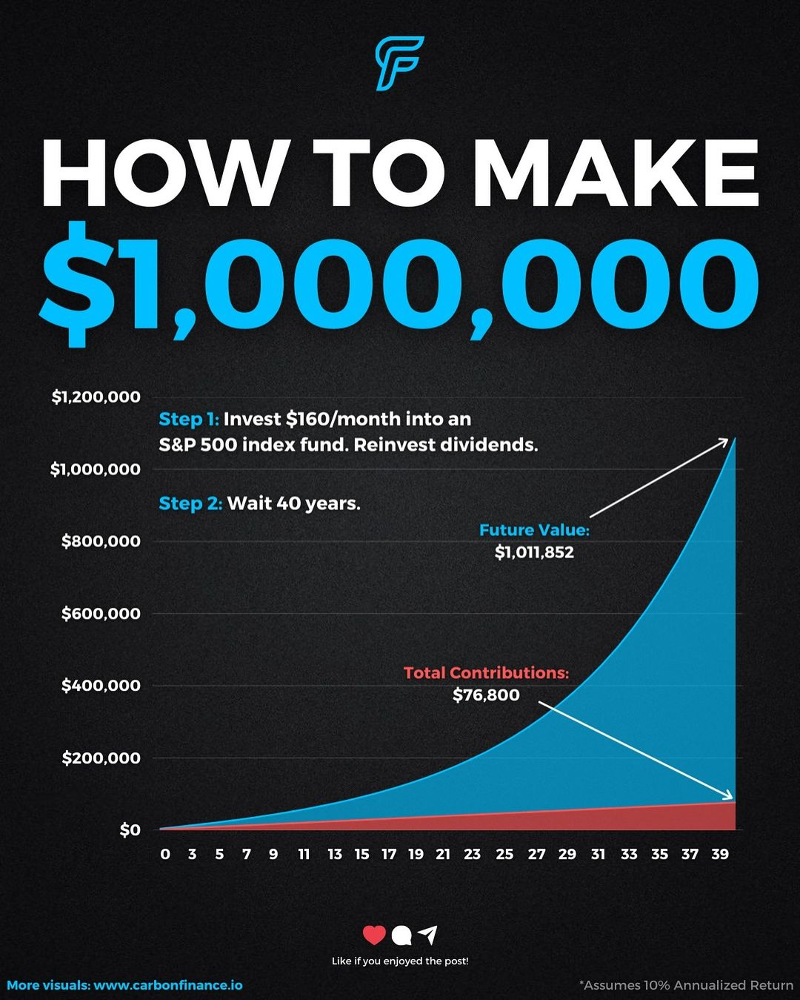

Ground Truth: Not_AI
Model Prediction: Not_AI (Confidence: 0.7976)

--------------------------------------------------



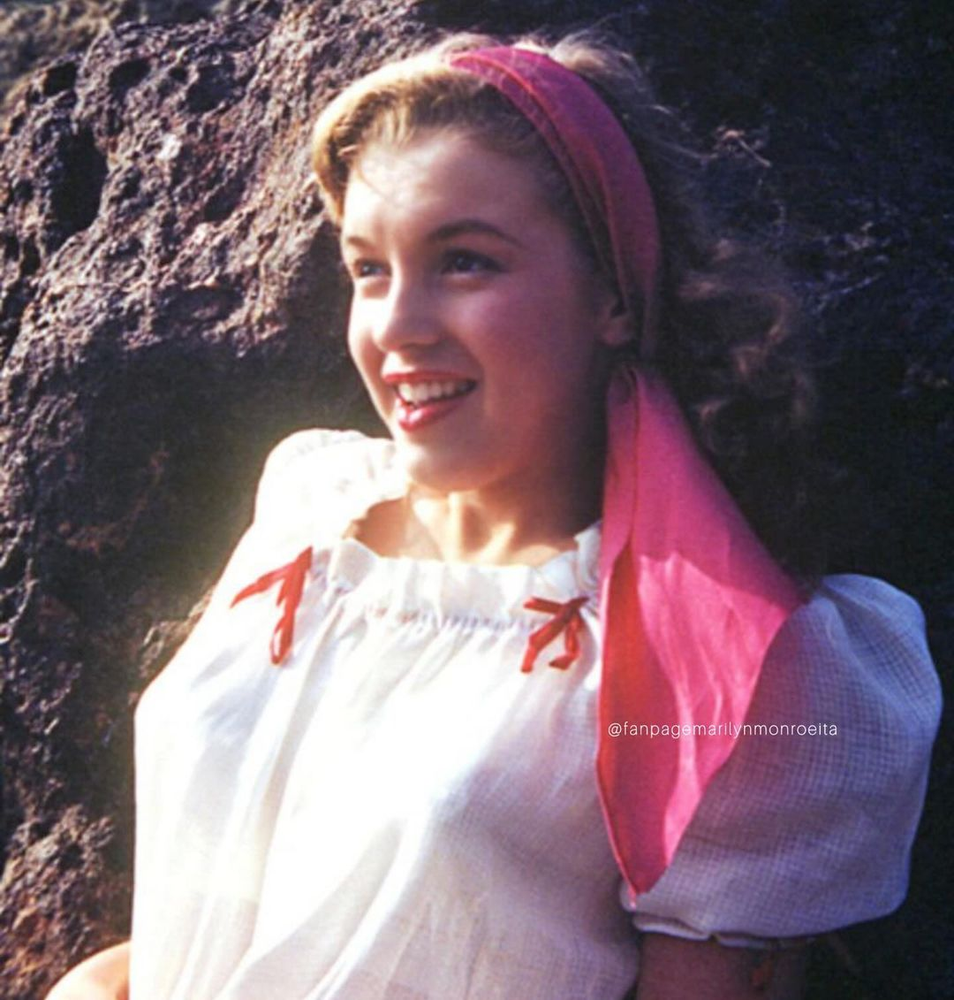

Ground Truth: Not_AI
Model Prediction: Not_AI (Confidence: 0.8477)

--------------------------------------------------



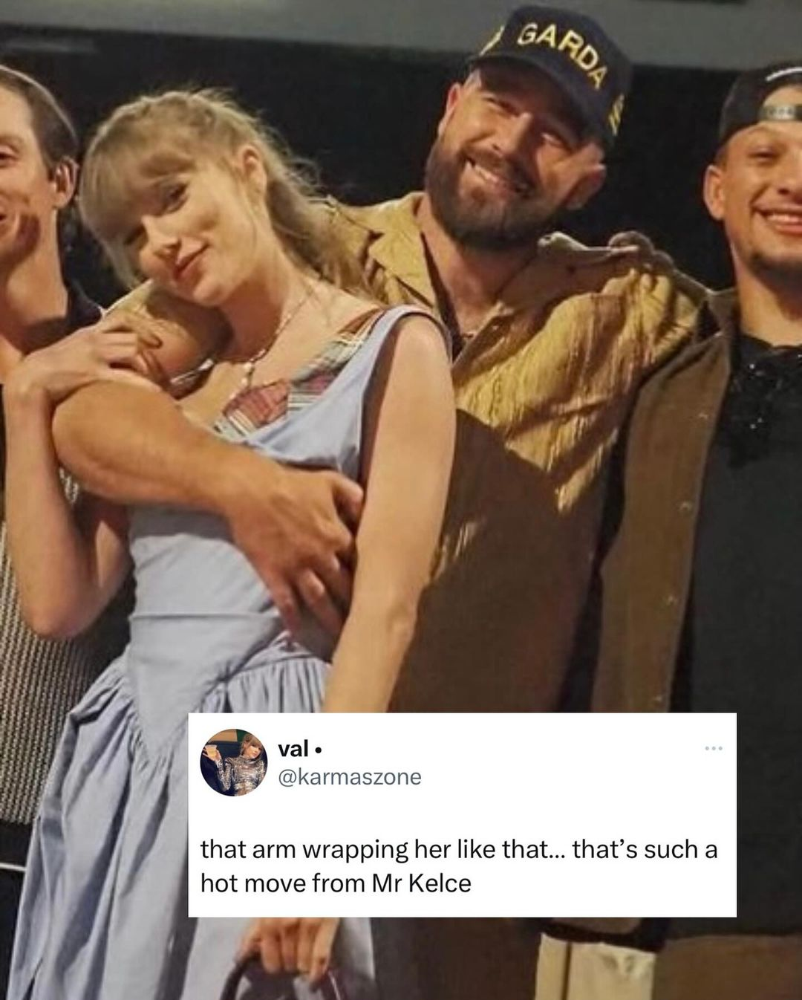

Ground Truth: Not_AI
Model Prediction: Not_AI (Confidence: 0.7064)

--------------------------------------------------



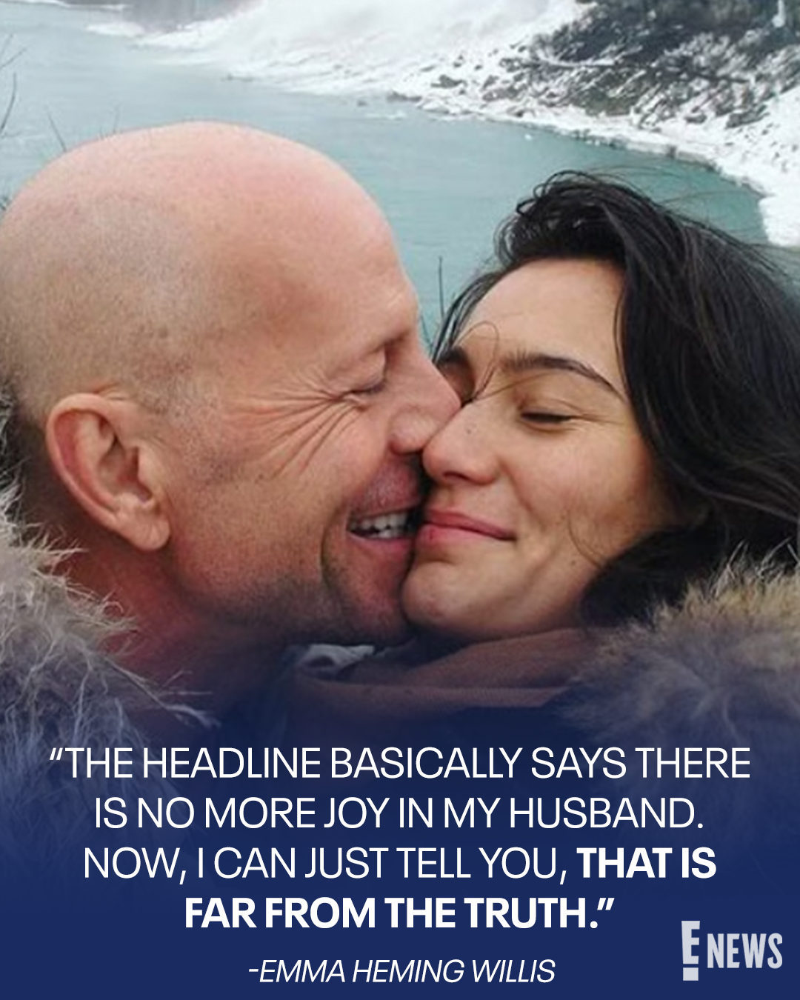

Ground Truth: Not_AI
Model Prediction: Not_AI (Confidence: 0.7163)

--------------------------------------------------



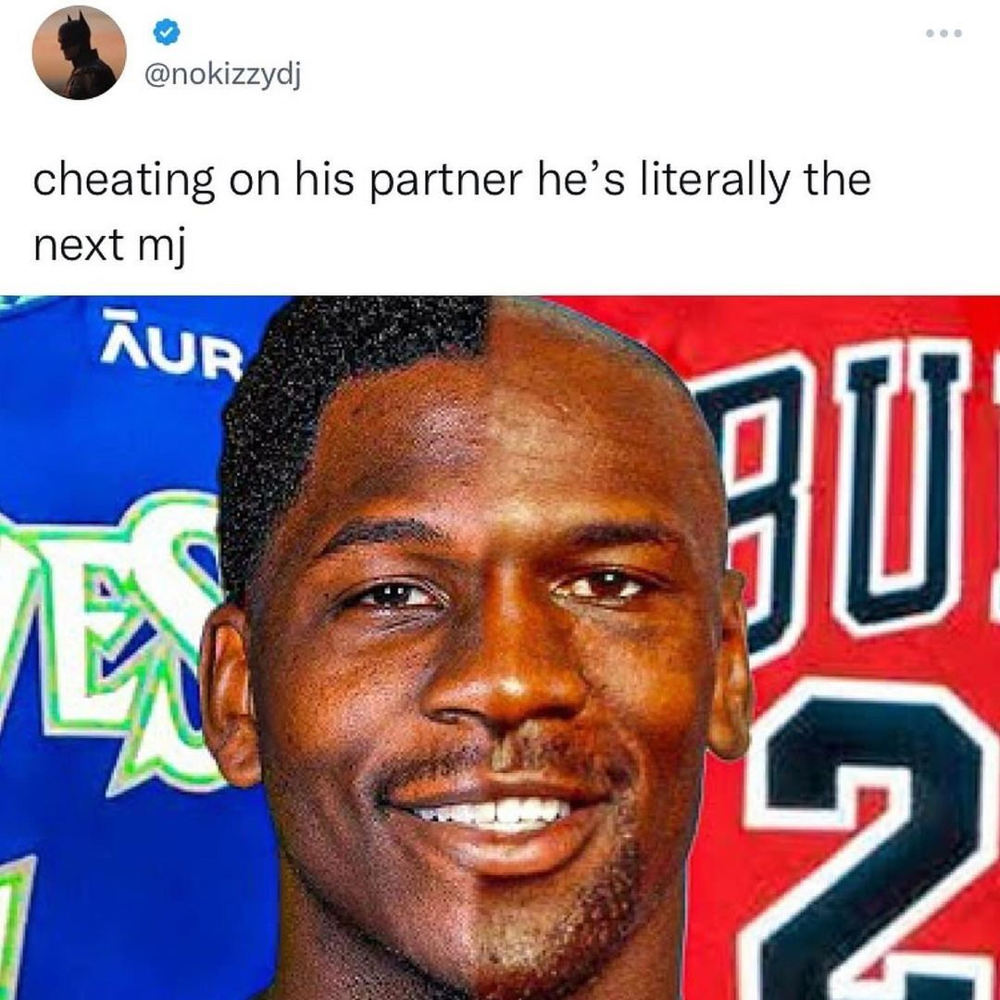

Ground Truth: Not_AI
Model Prediction: Not_AI (Confidence: 0.8970)

--------------------------------------------------



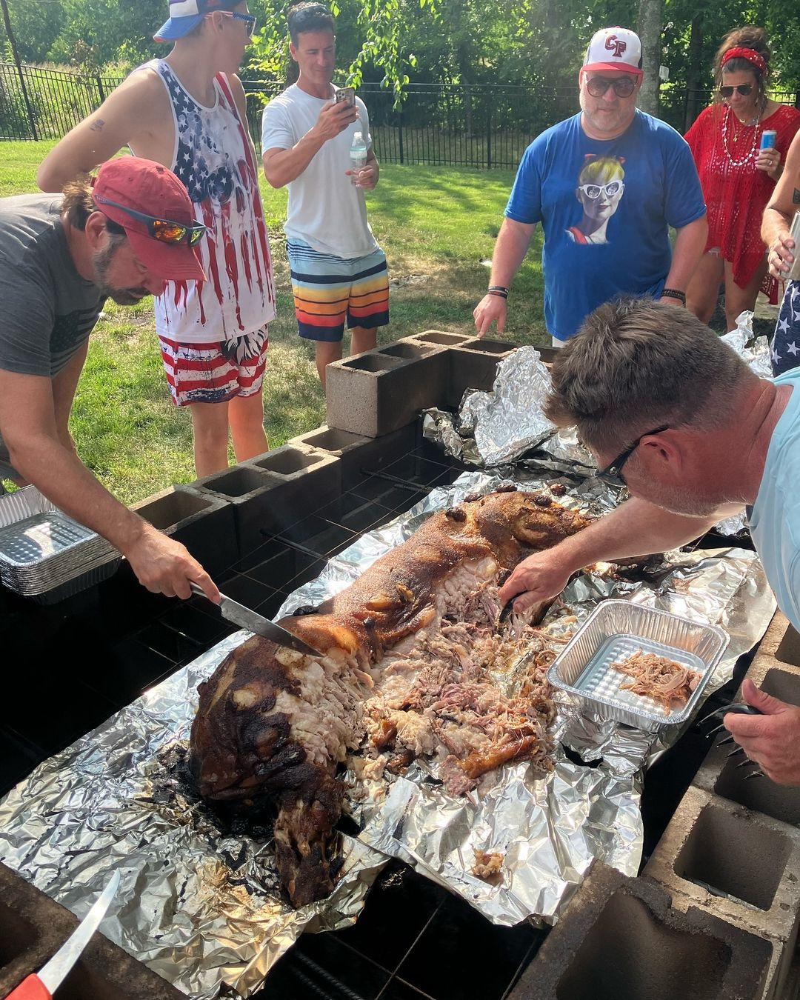

Ground Truth: Not_AI
Model Prediction: Not_AI (Confidence: 0.5468)

--------------------------------------------------



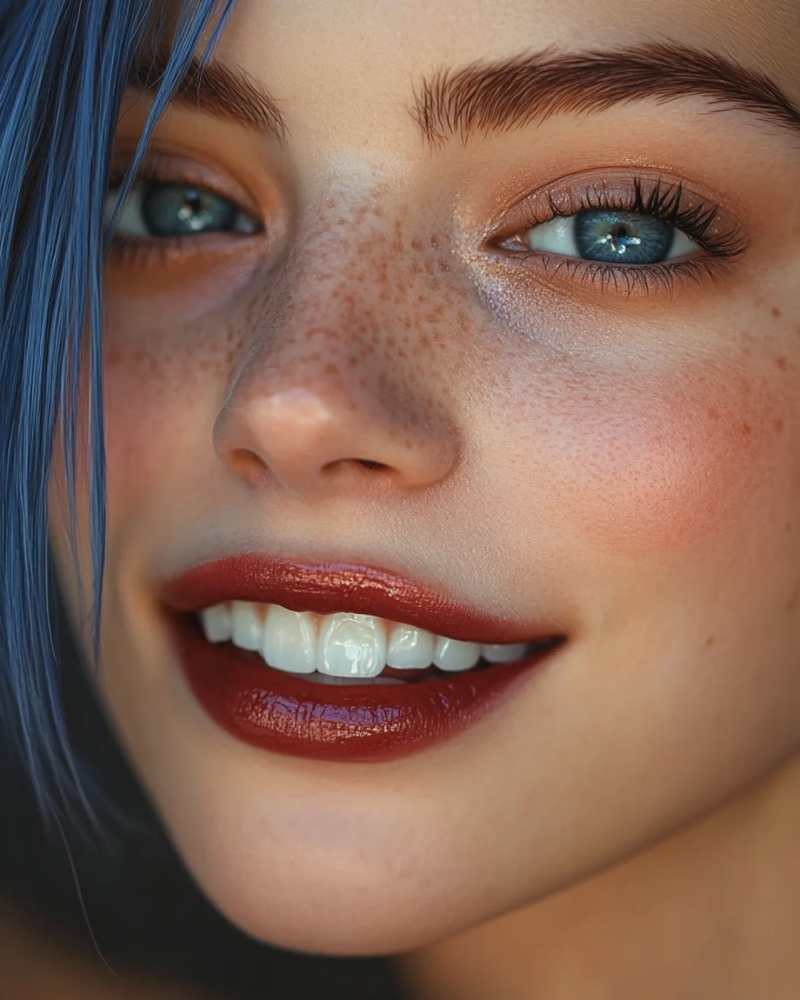

Ground Truth: AI
Model Prediction: AI (Confidence: 0.9531)

--------------------------------------------------



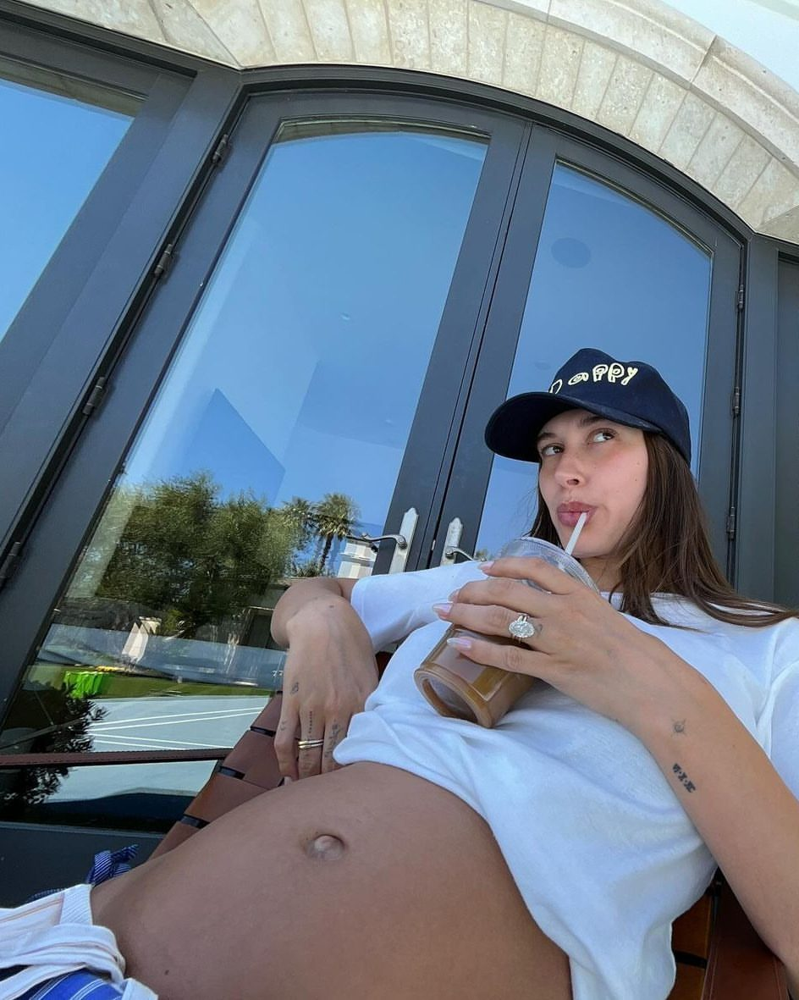

Ground Truth: Not_AI
Model Prediction: AI (Confidence: 0.5548)

--------------------------------------------------



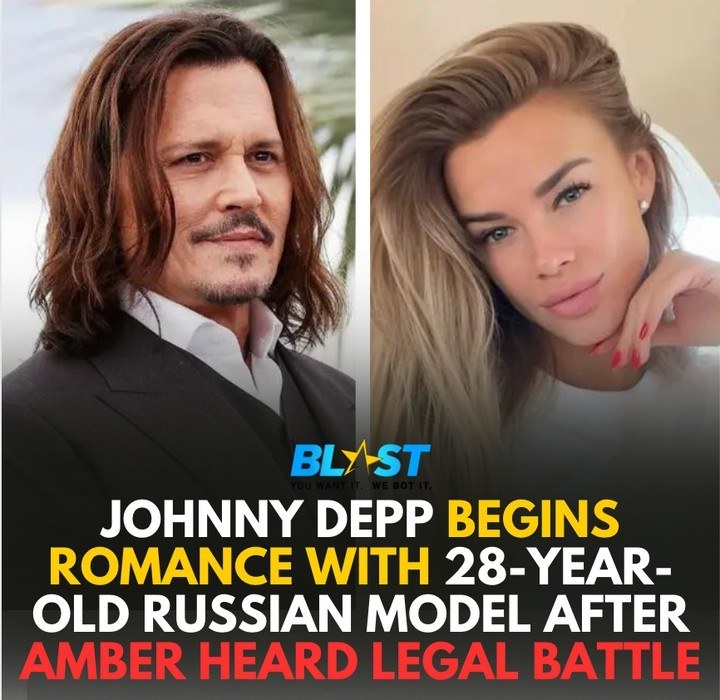

Ground Truth: Not_AI
Model Prediction: Not_AI (Confidence: 0.6001)

--------------------------------------------------



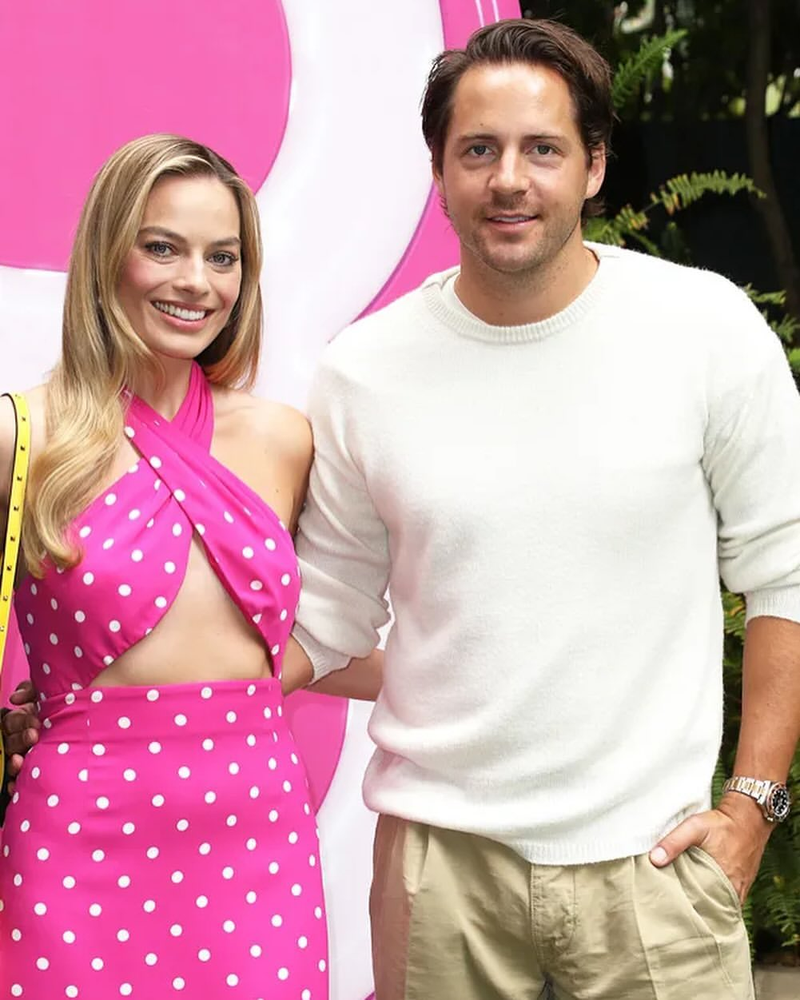

Ground Truth: Not_AI
Model Prediction: AI (Confidence: 0.5027)

--------------------------------------------------



In [ ]:
combined_model_save_path = ROOT / "finetuned_combined_model.pth"
loaded_exif_model = combined_model.to(DEVICE)
loaded_exif_model.load_state_dict(torch.load(combined_model_save_path, map_location=DEVICE))

loaded_exif_model.eval()

num_samples = min(10, len(combined_test_items))
if num_samples == 0:
    print("No test items available for visualization.")
else:
    random_test_samples = random.sample(combined_test_items, num_samples)

    print(f"Displaying {num_samples} random test images with ground truth and model predictions...")

    for i, (image_path, ground_truth_label_idx, _) in enumerate(random_test_samples):
        img = PILImage.open(image_path).convert("RGB")

        inputs = processor(images=img, return_tensors="pt")
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

        metadata_vector = METADATA_LOOKUP_TEST.get(str(image_path))
        if metadata_vector is None:
            metadata_vector = np.zeros(combined_model.metadata_mlp[0].in_features, dtype=np.float32)
        metadata_features = torch.tensor(metadata_vector, dtype=torch.float).unsqueeze(0).to(DEVICE)

        # Perform inference
        with torch.no_grad():
            outputs = loaded_exif_model(pixel_values=inputs['pixel_values'], metadata_features=metadata_features)
            logits = outputs
            probs = torch.softmax(logits, dim=-1)
            predicted_idx = logits.argmax(dim=-1).item()
            predicted_confidence = probs[0, predicted_idx].item()

        ground_truth_label_str = idx_to_class[ground_truth_label_idx]
        predicted_label_str = idx_to_class[predicted_idx]

        display(HTML(f"<h3>Sample {i + 1}: {image_path.name}</h3>"))
        display(img)
        print(f"Ground Truth: {ground_truth_label_str}")
        print(f"Model Prediction: {predicted_label_str} (Confidence: {predicted_confidence:.4f})")
        print("\n" + "-"*50 + "\n")

In [ ]:
combined_model_save_path = ROOT / "finetuned_combined_model.pth"
torch.save(combined_model.state_dict(), combined_model_save_path)
print(f"Finetuned Combined Model saved to {combined_model_save_path}")

Finetuned Combined Model saved to /content/drive/MyDrive/Project 1-1/Dataset/finetuned_combined_model.pth


## COMBINED MODEL: CNN + SOCIAL MEDIA METADATA

In [ ]:
AI_CLASS_WEIGHT = 3.0
FINETUNE_EPOCHS = 25
LR = 5e-5

In [ ]:
BERT_MODEL_NAME = 'bert-base-multilingual-cased'
tokenizer = BertTokenizer.from_pretrained(BERT_MODEL_NAME)
bert_model = BertModel.from_pretrained(BERT_MODEL_NAME).to(DEVICE)
# Freeze BERT parameters
for param in bert_model.parameters():
    param.requires_grad = False
print(f"BERT model ({BERT_MODEL_NAME}) loaded and parameters frozen.")

BERT model (bert-base-multilingual-cased) loaded and parameters frozen.


In [ ]:
TEXT_LOOKUP = {}

def load_and_preprocess_metadata(metadata_filepaths: List[Path], image_root_dirs: List[Path]) -> Tuple[Dict[str, np.ndarray], int]:
    all_dfs = []
    # Only 'like_count' column as numerical
    numerical_cols_to_process = ['like_count']

    for filepath in metadata_filepaths:
        if not filepath.exists():
            print(f"Warning: Metadata file not found at {filepath}. Skipping.")
            continue

        try:
            df = pd.read_csv(filepath)
        except Exception as e:
            print(f"Error reading {filepath}: {e}. Skipping.")
            continue

        if 'post_name' in df.columns:
            df = df.rename(columns={'post_name': 'filename'})
        if 'base_name' in df.columns:
            df = df.rename(columns={'base_name': 'filename'})

        if 'filename' not in df.columns:
            print(f"Warning: Metadata file {filepath} does not contain a 'filename' or 'post_name' column. Skipping this file for combined model.")
            continue

        for col in numerical_cols_to_process:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors='coerce')
            else:
                df[col] = np.nan

        actual_text_col = None
        if 'post_text' in df.columns:
            actual_text_col = 'post_text'
        elif 'caption_text' in df.columns:
            actual_text_col = 'caption_text'

        if actual_text_col:
            print(f"Found text column '{actual_text_col}' in {filepath.name}")
            for _, row in df.iterrows():
                filename = row['filename']
                text_content = str(row[actual_text_col]) if pd.notna(row[actual_text_col]) else ""

                image_path = None
                for root_dir in image_root_dirs:
                    potential_path = root_dir / filename
                    if potential_path.exists():
                        image_path = potential_path
                        break
                    if root_dir == LABELED_DIR or root_dir == TEST_SET_DIR:
                        for sub_dir in root_dir.iterdir():
                            if sub_dir.is_dir():
                                potential_sub_path = sub_dir / filename
                                if potential_sub_path.exists():
                                    image_path = potential_sub_path
                                    break
                            if image_path:
                                break

                if image_path:
                    TEXT_LOOKUP[str(image_path)] = text_content
        else:
            print(f"Warning: Neither 'post_text' nor 'caption_text' found in {filepath}. Text features will be empty for this file.")

        all_dfs.append(df)

    if not all_dfs:
        print("No valid metadata files loaded or processed. Returning empty numerical lookup.")
        return {}, 0

    combined_df = pd.concat(all_dfs, ignore_index=True)

    final_numerical_cols = [col for col in numerical_cols_to_process if col in combined_df.columns]

    if not final_numerical_cols:
        print("Warning: No valid numerical columns found for feature extraction across all metadata files. Numerical features will be empty.")
        return {}, 0

    for col in final_numerical_cols:
        combined_df[col] = combined_df[col].fillna(combined_df[col].mean())

    # Normalize the final set of numerical columns
    scaler = MinMaxScaler()
    combined_df[final_numerical_cols] = scaler.fit_transform(combined_df[final_numerical_cols])

    metadata_lookup = {}
    for _, row in combined_df.iterrows():
        filename = row['filename']
        image_path = None

        for root_dir in image_root_dirs:
            potential_path = root_dir / filename
            if potential_path.exists():
                image_path = potential_path
                break
            if root_dir == LABELED_DIR or root_dir == TEST_SET_DIR:
                for sub_dir in root_dir.iterdir():
                    if sub_dir.is_dir():
                        potential_sub_path = sub_dir / filename
                        if potential_sub_path.exists():
                            image_path = potential_sub_path
                            break
                    if image_path:
                        break

        if image_path is None:
            continue

        normalized_features = []
        for col in final_numerical_cols:
            normalized_features.append(row[col])

        metadata_lookup[str(image_path)] = np.array(normalized_features, dtype=np.float32)

    return metadata_lookup, len(final_numerical_cols)

metadata_files = [
    METADATA_ROOT / "socialmedia_metadata (1).csv",
    METADATA_ROOT / "SOCIALMEDIA METADATA" / "TEST_NOTAI_SOCIALMEDIA.csv",
    METADATA_ROOT / "SOCIALMEDIA METADATA" / "SOCIALMEDIA_AI_TEST_FINAL.csv",
    METADATA_ROOT / "SOCIALMEDIA_AI_NEW.csv"
]
METADATA_LOOKUP, METADATA_FEATURE_SIZE = load_and_preprocess_metadata(metadata_files, [LABELED_DIR, UNLABELED_DIR, TEST_SET_DIR])
print(f"Loaded and preprocessed metadata for {len(METADATA_LOOKUP)} images. Total feature size: {METADATA_FEATURE_SIZE}")
print("First 5 entries of METADATA_LOOKUP:")
for i, (k, v) in enumerate(METADATA_LOOKUP.items()):
    if i >= 5: break
    print(f"  {k}: {v}")
print("First 5 entries of TEXT_LOOKUP:")
for i, (k, v) in enumerate(TEXT_LOOKUP.items()):
    if i >= 5: break
    print(f"  {k}: {v}")


Found text column 'post_text' in socialmedia_metadata (1).csv
Found text column 'post_text' in TEST_NOTAI_SOCIALMEDIA.csv
Found text column 'caption_text' in SOCIALMEDIA_AI_TEST_FINAL.csv
Found text column 'caption_text' in SOCIALMEDIA_AI_NEW.csv
Loaded and preprocessed metadata for 591 images. Total feature size: 1
First 5 entries of METADATA_LOOKUP:
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/annabelle_o.j_3404045924671036209.jpg: [8.087311e-06]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/indypersian_lifestyle_3408995233012153899.jpg: [0.00730284]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/entertainmenttonight_3409047080926652141.jpg: [0.00915888]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/backgrid_usa_3408704630247554963.jpg: [8.087311e-06]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/backgrid_usa_3408704671234267147.jpg: [8.087311e-06]
First 5 entries of TEXT_LOOKUP:
  /content/drive/MyDrive/

In [ ]:
FINAL_COMBINED_DATASET_CSV = ROOT / "final_combined_dataset.csv"

if 'METADATA_LOOKUP' not in globals():
    METADATA_ROOT = ROOT / "METADATA"
    metadata_files = [
        METADATA_ROOT / "socialmedia_metadata (1).csv",
        METADATA_ROOT / "SOCIALMEDIA METADATA" / "TEST_NOTAI_SOCIALMEDIA.csv",
        METADATA_ROOT / "SOCIALMEDIA METADATA" / "SOCIALMEDIA_AI_TEST_FINAL.csv"
    ]
    METADATA_LOOKUP = load_and_preprocess_metadata(metadata_files, LABELED_DIR, UNLABELED_DIR)
    print(f"METADATA_LOOKUP was not defined, re-initialized with {len(METADATA_LOOKUP)} entries.")

raw_combined_df = pd.read_csv(FINAL_COMBINED_DATASET_CSV)
metadata_available_paths = set(METADATA_LOOKUP.keys())
filtered_df = raw_combined_df[raw_combined_df['image_path'].isin(metadata_available_paths)].copy()

print(f"Original combined dataset size: {len(raw_combined_df)} samples")
print(f"Filtered dataset size (with available metadata): {len(filtered_df)} samples")

if 'class_to_idx' not in globals():
    _, class_to_idx = build_labeled_items(LABELED_DIR)
filtered_df['numerical_label'] = filtered_df['label'].map(class_to_idx)

Original combined dataset size: 1323 samples
Filtered dataset size (with available metadata): 530 samples


In [ ]:
print('Class balance in the filtered dataset (images with metadata and pseudo-labels):')
class_counts = filtered_df['numerical_label'].value_counts()

idx_to_class = {v: k for k, v in class_to_idx.items()}
class_balance_df = pd.DataFrame({
    'Class': class_counts.index.map(idx_to_class),
    'Count': class_counts.values,
    'Percentage': (class_counts.values / len(filtered_df)) * 100
})

display(class_balance_df)
print(f"Total samples in filtered dataset: {len(filtered_df)}")

Class balance in the filtered dataset (images with metadata and pseudo-labels):


,Class,Count,Percentage
0,Not_AI,395,74.528302
1,AI,135,25.471698


Total samples in filtered dataset: 530


In [ ]:
class CombinedImageMetadataDataset(SimpleImageDataset):
    def __init__(self, items: List[Tuple[Path, int, float]], metadata_lookup: Dict[str, np.ndarray], text_lookup: Dict[str, str], metadata_feature_size: int):
        super().__init__(items)
        self.metadata_lookup = metadata_lookup
        self.text_lookup = text_lookup
        self.metadata_vector_size = metadata_feature_size

    def __getitem__(self, idx):
        img, label, path_str, sweight = super().__getitem__(idx)

        # Numerical metadata
        metadata_vector = self.metadata_lookup.get(path_str)
        if metadata_vector is None:
            metadata_vector = np.zeros(self.metadata_vector_size, dtype=np.float32)

        # Text metadata
        post_text = self.text_lookup.get(path_str, "")

        return img, label, path_str, sweight, metadata_vector, post_text

def collate_for_combined_model(batch):
    images = [b[0] for b in batch]
    labels = torch.tensor([b[1] for b in batch], dtype=torch.long)
    paths = [b[2] for b in batch]
    sample_weights = torch.tensor([b[3] for b in batch], dtype=torch.float)
    metadata_vectors_np = [b[4] for b in batch]
    post_texts = [b[5] for b in batch]

    metadata_features = torch.tensor(np.stack(metadata_vectors_np), dtype=torch.float)

    # Process images
    image_inputs = processor(images=images, return_tensors="pt")
    image_inputs = {k: v.to(DEVICE) for k, v in image_inputs.items()}

    # Process text
    tokenized_text = tokenizer(
        post_texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )
    text_input_ids = tokenized_text['input_ids'].to(DEVICE)
    text_attention_mask = tokenized_text['attention_mask'].to(DEVICE)

    labels = labels.to(DEVICE)
    sample_weights = sample_weights.to(DEVICE)
    metadata_features = metadata_features.to(DEVICE)

    return image_inputs, labels, paths, sample_weights, metadata_features, text_input_ids, text_attention_mask


In [ ]:
class CombinedModel(nn.Module):
    def __init__(self, cnn_model, bert_model, metadata_feature_size: int, num_labels: int = 2, freeze_cnn_features: bool = True):
        super().__init__()
        self.cnn_feature_extractor = cnn_model.vision_model

        if hasattr(cnn_model, 'classifier') and hasattr(cnn_model.classifier, 'in_features'):
            self.cnn_feature_output_size = cnn_model.classifier.in_features
        elif hasattr(cnn_model, 'config') and hasattr(cnn_model.config, 'hidden_size'):
            self.cnn_feature_output_size = cnn_model.config.hidden_size
        else:
            raise ValueError("Could not determine CNN feature output size from cnn_model.")

        if freeze_cnn_features:
            for param in self.cnn_feature_extractor.parameters():
                param.requires_grad = False
            print(f"CNN feature extractor parameters frozen: {freeze_cnn_features}")

        # Numerical metadata MLP
        self.metadata_mlp = nn.Sequential(
            nn.Linear(metadata_feature_size, self.cnn_feature_output_size // 4),
            nn.ReLU(),
            nn.Linear(self.cnn_feature_output_size // 4, self.cnn_feature_output_size // 4)
        )

        # Text embedding component
        self.bert_model = bert_model
        self.bert_output_size = self.bert_model.config.hidden_size
        # Project BERT output to a compatible size
        self.text_projection = nn.Linear(self.bert_output_size, self.cnn_feature_output_size // 2)


        # Final classifier takes concatenated features
        total_combined_feature_size = self.cnn_feature_output_size + (self.cnn_feature_output_size // 4) + (self.cnn_feature_output_size // 2)
        self.classifier = nn.Linear(total_combined_feature_size, num_labels)

    def forward(self, pixel_values, metadata_features, text_input_ids, text_attention_mask):
        # Image features
        cnn_outputs = self.cnn_feature_extractor(pixel_values=pixel_values, output_hidden_states=True, return_dict=True)
        if hasattr(cnn_outputs, 'last_hidden_state') and cnn_outputs.last_hidden_state is not None:
            image_features = cnn_outputs.last_hidden_state[:, 0, :]
        elif hasattr(cnn_outputs, 'pooled_output') and cnn_outputs.pooled_output is not None:
            image_features = cnn_outputs.pooled_output
        else:
            raise ValueError("Could not extract image features from CNN output. Neither last_hidden_state nor pooled_output available.")

        # Numerical metadata features
        processed_metadata_features = self.metadata_mlp(metadata_features)

        # Text features (BERT outputs)
        text_outputs = self.bert_model(input_ids=text_input_ids, attention_mask=text_attention_mask, return_dict=True)
        text_embeddings = self.text_projection(text_outputs.pooler_output)

        # Concatenate all features
        combined_features = torch.cat((image_features, processed_metadata_features, text_embeddings), dim=-1)

        logits = self.classifier(combined_features)
        return logits

def finetune_combined_model(model, train_items: List[Tuple[Path,int,float]],
                   val_loader: DataLoader = None,
                   class_weight: float = AI_CLASS_WEIGHT,
                   epochs: int = FINETUNE_EPOCHS,
                   batch_size: int = BATCH_SIZE,
                   lr: float = LR,
                   patience: int = 2):
    ds = CombinedImageMetadataDataset(train_items, METADATA_LOOKUP, TEXT_LOOKUP, METADATA_FEATURE_SIZE)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, collate_fn=collate_for_combined_model, num_workers=0)

    class_weights = torch.tensor([1.0, float(class_weight)], dtype=torch.float).to(DEVICE)
    criterion = nn.CrossEntropyLoss(reduction='none', weight=class_weights)

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)

    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        n_samples = 0
        for image_inputs, labels, paths, sample_weights, metadata_features, text_input_ids, text_attention_mask in loader:
            outputs_logits = model(pixel_values=image_inputs['pixel_values'], metadata_features=metadata_features,
                                   text_input_ids=text_input_ids, text_attention_mask=text_attention_mask)
            losses = criterion(outputs_logits, labels)
            weighted_losses = losses * sample_weights
            loss = weighted_losses.mean()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += float(loss.item()) * outputs_logits.shape[0]
            n_samples += outputs_logits.shape[0]

        avg_train_loss = epoch_loss / max(1, n_samples)
        print(f"[finetune_combined] epoch {epoch+1}/{epochs} avg_train_loss={avg_train_loss:.5f}")

        if val_loader:
            model.eval()
            val_loss = 0.0
            val_n_samples = 0
            with torch.no_grad():
                for image_inputs, labels, paths, sample_weights, metadata_features, text_input_ids, text_attention_mask in val_loader:
                    outputs_logits = model(pixel_values=image_inputs['pixel_values'], metadata_features=metadata_features,
                                           text_input_ids=text_input_ids, text_attention_mask=text_attention_mask)
                    losses = criterion(outputs_logits, labels)
                    val_loss += float(losses.mean().item()) * outputs_logits.shape[0]
                    val_n_samples += outputs_logits.shape[0]
            avg_val_loss = val_loss / max(1, val_n_samples)
            print(f"[finetune_combined] Validation Loss: {avg_val_loss:.5f}")

            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                epochs_no_improve = 0
                best_model_state = model.state_dict()
            else:
                epochs_no_improve += 1
                print(f"[finetune_combined] No improvement in validation loss for {epochs_no_improve} epochs.")

            if epochs_no_improve >= patience:
                print(f"[finetune_combined] Early stopping triggered after {patience} epochs without improvement.")
                break

    if best_model_state:
        model.load_state_dict(best_model_state)
        print("[finetune_combined] Loaded best model state based on validation loss.")
    return model
combined_model = CombinedModel(cnn_model=model, bert_model = bert_model, metadata_feature_size=metadata_feature_size, num_labels=2, freeze_cnn_features=True)
combined_model.to(DEVICE)

print("CombinedModel instantiated and moved to device.")
print(combined_model)

CNN feature extractor parameters frozen: True
CombinedModel instantiated and moved to device.
CombinedModel(
  (cnn_feature_extractor): SiglipVisionTransformer(
    (embeddings): SiglipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), padding=valid)
      (position_embedding): Embedding(196, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (self_attn): SiglipAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (mlp): SiglipMLP(
          

In [ ]:
@torch.no_grad()
def predict_combined_social_media_dataset(model: nn.Module, dataloader: DataLoader) -> List[Dict]:
    model.eval()
    out = []
    for image_inputs, labels, paths, sample_weights, metadata_features, text_input_ids, text_attention_mask in dataloader:
        pixel_values = image_inputs['pixel_values']
        outputs = model(pixel_values=pixel_values, metadata_features=metadata_features,
                        text_input_ids=text_input_ids, text_attention_mask=text_attention_mask)
        logits = outputs
        probs = torch.softmax(logits, dim=-1).cpu()
        pred_idx = logits.argmax(-1).cpu()
        batch_size = logits.shape[0]
        for i in range(batch_size):
            pi = int(pred_idx[i].item())
            conf = float(probs[i, pi].item())
            out.append({
                "image_path": paths[i],
                "pred_idx": pi,
                "confidence": conf,
                "ground_truth": labels[i].item()
            })
    return out

def evaluate_combined_social_media_model_metrics(model: nn.Module, dataloader: DataLoader, idx_to_class: dict, phase: str = "Evaluation"):

    model.eval()

    print(f"[{phase}] Starting evaluation for {len(dataloader.dataset)} samples...")

    predictions_results = predict_combined_social_media_dataset(model, dataloader)

    all_preds = [item['pred_idx'] for item in predictions_results]
    all_labels = [item['ground_truth'] for item in predictions_results]

    print(f"[{phase}] Total collected labels: {len(all_labels)}")
    print(f"[{phase}] Total collected predictions: {len(all_preds)}")

    if len(all_labels) == 0 or len(all_preds) == 0:
        print(f"[{phase}] No samples found for evaluation. Skipping metric calculation.")
        print(f"--- {phase} Metrics ---")
        print(f"Accuracy: N/A")
        print(f"Precision (AI): N/A")
        print(f"Recall (AI): N/A")
        print(f"F1-Score (AI): N/A")
        print("Confusion Matrix: N/A")
        print("-----------------------")
        return

    pos_label_idx = 1
    neg_label_idx = 0
    pos_label_name = idx_to_class.get(pos_label_idx, str(pos_label_idx))
    neg_label_name = idx_to_class.get(neg_label_idx, str(neg_label_idx))

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, pos_label=pos_label_idx, average='binary', zero_division=0)
    recall = recall_score(all_labels, all_preds, pos_label=pos_label_idx, average='binary', zero_division=0)
    f1 = f1_score(all_labels, all_preds, pos_label=pos_label_idx, average='binary', zero_division=0)

    cm = confusion_matrix(all_labels, all_preds, labels=[pos_label_idx, neg_label_idx])

    print(f"--- {phase} Metrics ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision ({pos_label_name}): {precision:.4f}")
    print(f"Recall ({pos_label_name}): {recall:.4f}")
    print(f"F1-Score ({pos_label_name}): {f1:.4f}")
    print("\nConfusion Matrix:")
    print(f"{'':<10} {pos_label_name:<10} {neg_label_name:<10}")
    print(f"{'':-<10}-{'':-<10}-{'':-<10}")
    print(f"{pos_label_name:<10}| {cm[0, 0]:<10} {cm[0, 1]:<10}")
    print(f"{neg_label_name:<10}| {cm[1, 0]:<10} {cm[1, 1]:<10}")
    print("-----------------------")

In [ ]:
raw_combined_df = pd.read_csv(FINAL_COMBINED_DATASET_CSV)
# Filter the images that have both numerical and text metadata
metadata_and_text_available_paths = set(METADATA_LOOKUP.keys()).intersection(set(TEXT_LOOKUP.keys()))
filtered_df = raw_combined_df[raw_combined_df['image_path'].isin(metadata_and_text_available_paths)].copy()
if class_to_idx:
    filtered_df['numerical_label'] = filtered_df['label'].map(class_to_idx)
else:
    print("Warning: class_to_idx is empty. Cannot map labels to numerical. `numerical_label` column will not be created.")
    filtered_df['numerical_label'] = -1

print(f"Original combined dataset size: {len(raw_combined_df)} samples")
print(f"Filtered dataset size (with available numerical & text metadata and mapped labels): {len(filtered_df)} samples")


Original combined dataset size: 1323 samples
Filtered dataset size (with available numerical & text metadata and mapped labels): 530 samples


In [ ]:
VAL_SIZE = 0.2
RANDOM_STATE = 42

# Split into training and validation
train_df, val_df = train_test_split(
    filtered_df,
    test_size=VAL_SIZE,
    random_state=RANDOM_STATE,
    stratify=filtered_df['numerical_label']
)

print(f"Combined Training Data (with metadata): {len(train_df)} samples")
print(f"Combined Validation Data (with metadata): {len(val_df)} samples")



def df_to_items(df: pd.DataFrame) -> list:
    items = []
    for _, row in df.iterrows():
        items.append((Path(row['image_path']), row['numerical_label'], LABELED_SAMPLE_WEIGHT))
    return items

combined_train_items = df_to_items(train_df)
combined_val_items = df_to_items(val_df)


combined_test_items = []
for path, label, sample_weight in labeled_test_items:
    if str(path) in METADATA_LOOKUP and str(path) in TEXT_LOOKUP:
        combined_test_items.append((path, label, sample_weight))

print(f"Items for Combined Model: Train={len(combined_train_items)}, Validation={len(combined_val_items)}, Test={len(combined_test_items)}")


combined_train_ds = CombinedImageMetadataDataset(combined_train_items, METADATA_LOOKUP, TEXT_LOOKUP, METADATA_FEATURE_SIZE)
combined_val_ds = CombinedImageMetadataDataset(combined_val_items, METADATA_LOOKUP, TEXT_LOOKUP, METADATA_FEATURE_SIZE)
combined_test_ds = CombinedImageMetadataDataset(combined_test_items, METADATA_LOOKUP, TEXT_LOOKUP, METADATA_FEATURE_SIZE)

print("CombinedImageMetadataDataset instances created.")

combined_train_loader = DataLoader(
    combined_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_for_combined_model,
    num_workers=0
)

combined_val_loader = DataLoader(
    combined_val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_for_combined_model,
    num_workers=0
)

combined_test_loader = DataLoader(
    combined_test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_for_combined_model,
    num_workers=0
)

print("Combined DataLoaders created: combined_train_loader, combined_val_loader, combined_test_loader.")

Combined Training Data (with metadata): 424 samples
Combined Validation Data (with metadata): 106 samples
Items for Combined Model: Train=424, Validation=106, Test=49
CombinedImageMetadataDataset instances created.
Combined DataLoaders created: combined_train_loader, combined_val_loader, combined_test_loader.


In [ ]:
combined_model_save_path = ROOT / "finetuned_combined_social_model.pth"

if 'finetuned_combined_social_model' in globals():
    del combined_model
    print("Deleted 'combined_model' from global scope to force re-training.")

if combined_model_save_path.exists():
    print(f"Deleting existing model file: {combined_model_save_path} to force re-training.")
    combined_model_save_path.unlink()

if combined_train_loader is not None and combined_val_loader is not None and combined_test_loader is not None:
    print("CombinedModel not found. Re-instantiating and training...")
    combined_model = CombinedModel(cnn_model=model, bert_model=bert_model, metadata_feature_size=METADATA_FEATURE_SIZE, num_labels=2, freeze_cnn_features=True)
    combined_model.to(DEVICE)
    combined_model = finetune_combined_model(
        model=combined_model,
        train_items=combined_train_items,
        val_loader=combined_val_loader,
        class_weight=AI_CLASS_WEIGHT,
        epochs=FINETUNE_EPOCHS,
        batch_size=BATCH_SIZE,
        lr=LR,
        patience=2
    )
    print("Supervised training of CombinedModel complete!")
    torch.save(combined_model.state_dict(), combined_model_save_path)
    print(f"Finetuned Combined Model saved to {combined_model_save_path}")

    print("\nEvaluating CombinedModel on Test Data...")
    evaluate_combined_social_media_model_metrics(
        model=combined_model,
        dataloader=combined_test_loader,
        idx_to_class=idx_to_class,
        phase="Combined Model Final Test Data Evaluation"
    )
else:
    print("Skipping Combined Model training and evaluation due to missing data loaders. Please resolve dataset path issues.")

Deleting existing model file: /content/drive/MyDrive/Project 1-1/Dataset/finetuned_combined_social_model.pth to force re-training.
CombinedModel not found. Re-instantiating and training...
CNN feature extractor parameters frozen: True
[finetune_combined] epoch 1/25 avg_train_loss=0.97889
[finetune_combined] Validation Loss: 0.99965
[finetune_combined] epoch 2/25 avg_train_loss=0.95014
[finetune_combined] Validation Loss: 0.97548
[finetune_combined] epoch 3/25 avg_train_loss=0.93667
[finetune_combined] Validation Loss: 0.96564
[finetune_combined] epoch 4/25 avg_train_loss=0.92044
[finetune_combined] Validation Loss: 0.94973
[finetune_combined] epoch 5/25 avg_train_loss=0.90193
[finetune_combined] Validation Loss: 0.94186
[finetune_combined] epoch 6/25 avg_train_loss=0.89768
[finetune_combined] Validation Loss: 0.91916
[finetune_combined] epoch 7/25 avg_train_loss=0.87977
[finetune_combined] Validation Loss: 0.91058
[finetune_combined] epoch 8/25 avg_train_loss=0.86649
[finetune_combined

# Combined Pipeline EXIF + Social Media + CNN


In [ ]:
AI_CLASS_WEIGHT = 3
FINETUNE_EPOCHS = 25
LR = 5e-5

TEXT_LOOKUP = {}
METADATA_ROOT = ROOT / "METADATA"

exif_metadata_scaler = MinMaxScaler()
exif_metadata_ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
exif_metadata_feature_size = 0

def load_and_preprocess_exif_metadata(metadata_filepaths: List[Path], labeled_dir: Path, unlabeled_dir: Optional[Path] = None, current_scaler: Optional[MinMaxScaler] = None, current_ohe: Optional[OneHotEncoder] = None) -> Tuple[Dict[str, np.ndarray], MinMaxScaler, OneHotEncoder, int]:
    all_dfs = []

    for filepath in metadata_filepaths:
        df = pd.read_csv(filepath)
        if 'A' in df.columns:
            df = df.rename(columns={'A': 'filename'})
        all_dfs.append(df)

    combined_df = pd.concat(all_dfs, ignore_index=True)

    numerical_cols_base = ['filesize', 'Megapixels', 'ImageSize', 'XResolution', 'YResolution']
    categorical_cols = ['YCbCrSubSampling', 'EncodingProcess', 'dqt_fingerprint']

    numerical_cols_to_process = list(numerical_cols_base)
    if 'ImageSize' in combined_df.columns:
        combined_df['ImageSize_processed'] = combined_df['ImageSize'].apply(lambda x:
            int(x.split('x')[0]) * int(x.split('x')[1]) if isinstance(x, str) and 'x' in x else np.nan
        )
        combined_df['ImageRatio_processed'] = combined_df['ImageSize'].apply(lambda x:
            int(x.split('x')[0]) / int(x.split('x')[1]) if isinstance(x, str) and 'x' in x and int(x.split('x')[1]) != 0 else np.nan
        )

        if 'ImageSize' in numerical_cols_to_process:
            numerical_cols_to_process.remove('ImageSize')
        numerical_cols_to_process.append('ImageSize_processed')
        numerical_cols_to_process.append('ImageRatio_processed')
        numerical_cols_to_process = [col if col != 'ImageSize' else 'ImageSize_processed' for col in numerical_cols_base]
    else:
        numerical_cols_to_process = numerical_cols_base

    present_numerical_cols = [col for col in numerical_cols_to_process if col in combined_df.columns]
    present_categorical_cols = [col for col in categorical_cols if col in combined_df.columns]

    for col in present_numerical_cols:
        combined_df[col] = pd.to_numeric(combined_df[col], errors='coerce')
        if combined_df[col].isnull().any():
            mean_val = combined_df[col].mean()
            combined_df[col] = combined_df[col].fillna(mean_val)

    for col in present_categorical_cols:
        combined_df[col] = combined_df[col].fillna('missing').astype(str)

    scaler = current_scaler if current_scaler else MinMaxScaler()
    ohe = current_ohe if current_ohe else OneHotEncoder(handle_unknown='ignore', sparse_output=False)

    if present_numerical_cols:
        if current_scaler:
            scaled_numerical_features = scaler.transform(combined_df[present_numerical_cols])
        else:
            scaled_numerical_features = scaler.fit_transform(combined_df[present_numerical_cols])
    else:
        scaled_numerical_features = np.array([]).reshape(len(combined_df), 0)

    if present_categorical_cols:
        if current_ohe:
            ohe_features = ohe.transform(combined_df[present_categorical_cols])
        else:
            ohe_features = ohe.fit_transform(combined_df[present_categorical_cols])
    else:
        ohe_features = np.array([]).reshape(len(combined_df), 0)

    combined_processed_features = np.hstack((scaled_numerical_features, ohe_features))
    total_feature_size = combined_processed_features.shape[1]

    metadata_lookup = {}
    for idx, row in combined_df.iterrows():
        filename = row['filename']
        image_path = None

        labeled_path = labeled_dir / filename
        unlabeled_path = None
        if unlabeled_dir is not None:
            unlabeled_path = unlabeled_dir / filename

        if labeled_path.exists():
            image_path = labeled_path
        elif unlabeled_path is not None and unlabeled_path.exists():
            image_path = unlabeled_path
        else:
            for sub_dir in labeled_dir.iterdir():
                if sub_dir.is_dir():
                    labeled_sub_path = sub_dir / filename
                    if labeled_sub_path.exists():
                        image_path = labeled_sub_path
                        break
            if image_path is None:
                continue

        metadata_lookup[str(image_path)] = combined_processed_features[idx].astype(np.float32)

    return metadata_lookup, scaler, ohe, total_feature_size

exif_metadata_files = [
    METADATA_ROOT / "exif_metadata_final.csv",
    METADATA_ROOT / "exif_metadata_ai_new.csv"
]
exif_metadata_test_files = [
    METADATA_ROOT / "exif_metadata_test_ai_final.csv",
    METADATA_ROOT / "exif_metadata_test_notai_final.csv"
]

EXIF_METADATA_LOOKUP, exif_metadata_scaler, exif_metadata_ohe, EXIF_METADATA_FEATURE_SIZE = load_and_preprocess_exif_metadata(exif_metadata_files, LABELED_DIR, UNLABELED_DIR)
EXIF_METADATA_LOOKUP_TEST, _, _, _ = load_and_preprocess_exif_metadata(exif_metadata_test_files, TEST_SET_DIR, None, current_scaler=exif_metadata_scaler, current_ohe=exif_metadata_ohe)


print(f"Loaded and preprocessed EXIF metadata for {len(EXIF_METADATA_LOOKUP)} images. Total feature size: {EXIF_METADATA_FEATURE_SIZE}")
print("First 5 entries of EXIF_METADATA_LOOKUP:")
for i, (k, v) in enumerate(EXIF_METADATA_LOOKUP.items()):
    if i >= 5: break
    print(f"  {k}: {v}")
print("\nFirst 5 entries of EXIF_METADATA_LOOKUP_TEST:")
for i, (k, v) in enumerate(EXIF_METADATA_LOOKUP_TEST.items()):
    if i >= 5: break
    print(f"  {k}: {v}")


Loaded and preprocessed EXIF metadata for 549 images. Total feature size: 52
First 5 entries of EXIF_METADATA_LOOKUP:
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/davidgmcafee_3416696126743990946.jpg: [0.00911041 0.11332974 0.11420015 1.         1.         1.
 0.         0.         0.         1.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         1.         0.
 0.         0.         0.         0.        ]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/indypersian_lifestyle_3408463037860174183.jpg: [0.10044052 0.4603346  0.44449508 1.         1.         1.
 0.         0.         1.         0.         0.         0.
 0.         0.         0.         1. 

In [ ]:
SOCIAL_TEXT_LOOKUP = {}
SOCIAL_NUMERICAL_METADATA_SCALER = MinMaxScaler()

def load_and_preprocess_social_media_metadata(metadata_filepaths: List[Path], image_root_dirs: List[Path]) -> Tuple[Dict[str, np.ndarray], MinMaxScaler, int]:
    all_dfs = []
    numerical_cols_to_process = ['like_count']

    for filepath in metadata_filepaths:
        if not filepath.exists():
            print(f"Warning: Metadata file not found at {filepath}. Skipping.")
            continue

        try:
            df = pd.read_csv(filepath)
        except Exception as e:
            print(f"Error reading {filepath}: {e}. Skipping.")
            continue

        if 'post_name' in df.columns:
            df = df.rename(columns={'post_name': 'filename'})
        if 'base_name' in df.columns:
            df = df.rename(columns={'base_name': 'filename'})

        if 'filename' not in df.columns:
            print(f"Warning: Metadata file {filepath} does not contain a 'filename' or 'post_name' column. Skipping this file for combined model.")
            continue

        for col in numerical_cols_to_process:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors='coerce')
            else:
                df[col] = np.nan

        actual_text_col = None
        if 'post_text' in df.columns:
            actual_text_col = 'post_text'
        elif 'caption_text' in df.columns:
            actual_text_col = 'caption_text'

        if actual_text_col:
            print(f"Found text column '{actual_text_col}' in {filepath.name}")
            for _, row in df.iterrows():
                filename = row['filename']
                text_content = str(row[actual_text_col]) if pd.notna(row[actual_text_col]) else ""

                image_path = None
                for root_dir in image_root_dirs:
                    potential_path = root_dir / filename
                    if potential_path.exists():
                        image_path = potential_path
                        break
                    if root_dir == LABELED_DIR or root_dir == TEST_SET_DIR:
                        for sub_dir in root_dir.iterdir():
                            if sub_dir.is_dir():
                                potential_sub_path = sub_dir / filename
                                if potential_sub_path.exists():
                                    image_path = potential_sub_path
                                    break
                            if image_path:
                                break

                if image_path:
                    SOCIAL_TEXT_LOOKUP[str(image_path)] = text_content
        else:
            print(f"Warning: Neither 'post_text' nor 'caption_text' found in {filepath}. Text features will be empty for this file.")

        all_dfs.append(df)

    if not all_dfs:
        print("No valid metadata files loaded or processed. Returning empty numerical lookup.")
        return {}, MinMaxScaler(), 0

    combined_df = pd.concat(all_dfs, ignore_index=True)

    final_numerical_cols = [col for col in numerical_cols_to_process if col in combined_df.columns]

    if not final_numerical_cols:
        print("Warning: No valid numerical columns found for feature extraction across all metadata files. Numerical features will be empty.")
        return {}, MinMaxScaler(), 0

    for col in final_numerical_cols:
        combined_df[col] = combined_df[col].fillna(combined_df[col].mean())

    scaler = MinMaxScaler()
    global SOCIAL_NUMERICAL_METADATA_SCALER
    SOCIAL_NUMERICAL_METADATA_SCALER = scaler
    combined_df[final_numerical_cols] = scaler.fit_transform(combined_df[final_numerical_cols])

    metadata_lookup = {}
    for _, row in combined_df.iterrows():
        filename = row['filename']
        image_path = None

        for root_dir in image_root_dirs:
            potential_path = root_dir / filename
            if potential_path.exists():
                image_path = potential_path
                break
            if root_dir == LABELED_DIR or root_dir == TEST_SET_DIR:
                for sub_dir in root_dir.iterdir():
                    if sub_dir.is_dir():
                        potential_sub_path = sub_dir / filename
                        if potential_sub_path.exists():
                            image_path = potential_sub_path
                            break
                    if image_path:
                        break

        if image_path is None:
            continue

        normalized_features = []
        for col in final_numerical_cols:
            normalized_features.append(row[col])

        metadata_lookup[str(image_path)] = np.array(normalized_features, dtype=np.float32)

    return metadata_lookup, scaler, len(final_numerical_cols)

social_media_metadata_files = [
    METADATA_ROOT / "socialmedia_metadata (1).csv",
    METADATA_ROOT / "SOCIALMEDIA_AI_NEW.csv",
    METADATA_ROOT / "SOCIALMEDIA METADATA" / "TEST_NOTAI_SOCIALMEDIA.csv",
    METADATA_ROOT / "SOCIALMEDIA METADATA" / "SOCIALMEDIA_AI_TEST_FINAL.csv"
]
SOCIAL_NUMERICAL_METADATA_LOOKUP, SOCIAL_NUMERICAL_METADATA_SCALER, SOCIAL_NUMERICAL_METADATA_FEATURE_SIZE = load_and_preprocess_social_media_metadata(social_media_metadata_files, [LABELED_DIR, UNLABELED_DIR, TEST_SET_DIR])
print(f"Loaded and preprocessed SOCIAL MEDIA NUMERICAL metadata for {len(SOCIAL_NUMERICAL_METADATA_LOOKUP)} images. Total feature size: {SOCIAL_NUMERICAL_METADATA_FEATURE_SIZE}")
print("First 5 entries of SOCIAL_NUMERICAL_METADATA_LOOKUP:")
for i, (k, v) in enumerate(SOCIAL_NUMERICAL_METADATA_LOOKUP.items()):
    if i >= 5: break
    print(f"  {k}: {v}")
print("First 5 entries of SOCIAL_TEXT_LOOKUP:")
for i, (k, v) in enumerate(SOCIAL_TEXT_LOOKUP.items()):
    if i >= 5: break
    print(f"  {k}: {v}")


Found text column 'post_text' in socialmedia_metadata (1).csv
Found text column 'caption_text' in SOCIALMEDIA_AI_NEW.csv
Found text column 'post_text' in TEST_NOTAI_SOCIALMEDIA.csv
Found text column 'caption_text' in SOCIALMEDIA_AI_TEST_FINAL.csv
Loaded and preprocessed SOCIAL MEDIA NUMERICAL metadata for 591 images. Total feature size: 1
First 5 entries of SOCIAL_NUMERICAL_METADATA_LOOKUP:
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/annabelle_o.j_3404045924671036209.jpg: [8.087311e-06]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/indypersian_lifestyle_3408995233012153899.jpg: [0.00730284]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/entertainmenttonight_3409047080926652141.jpg: [0.00915888]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/backgrid_usa_3408704630247554963.jpg: [8.087311e-06]
  /content/drive/MyDrive/Project 1-1/Dataset/Images/Unlabeled/backgrid_usa_3408704671234267147.jpg: [8.087311e-06]
First 5 entries o

In [ ]:
class FinalCombinedDataset(SimpleImageDataset):
    def __init__(self,
                 items: List[Tuple[Path, int, float]],
                 exif_metadata_lookup: Dict[str, np.ndarray],
                 social_numerical_metadata_lookup: Dict[str, np.ndarray],
                 social_text_lookup: Dict[str, str],
                 exif_metadata_feature_size: int,
                 social_numerical_metadata_feature_size: int):
        super().__init__(items)
        self.exif_metadata_lookup = exif_metadata_lookup
        self.social_numerical_metadata_lookup = social_numerical_metadata_lookup
        self.social_text_lookup = social_text_lookup
        self.exif_metadata_vector_size = exif_metadata_feature_size
        self.social_numerical_metadata_vector_size = social_numerical_metadata_feature_size

    def __getitem__(self, idx):
        img, label, path_str, sweight = super().__getitem__(idx)
        exif_metadata_vector = self.exif_metadata_lookup.get(path_str)
        if exif_metadata_vector is None:
            exif_metadata_vector = np.zeros(self.exif_metadata_vector_size, dtype=np.float32)

        social_numerical_metadata_vector = self.social_numerical_metadata_lookup.get(path_str)
        if social_numerical_metadata_vector is None:
            social_numerical_metadata_vector = np.zeros(self.social_numerical_metadata_vector_size, dtype=np.float32)

        social_text = self.social_text_lookup.get(path_str, "")

        return img, label, path_str, sweight, exif_metadata_vector, social_numerical_metadata_vector, social_text

print("FinalCombinedDataset class defined successfully.")


FinalCombinedDataset class defined successfully.


In [ ]:
def collate_for_final_combined_model(batch):
    images = [b[0] for b in batch]
    labels = torch.tensor([b[1] for b in batch], dtype=torch.long)
    paths = [b[2] for b in batch]
    sample_weights = torch.tensor([b[3] for b in batch], dtype=torch.float)
    exif_metadata_vectors_np = [b[4] for b in batch]
    social_numerical_metadata_vectors_np = [b[5] for b in batch]
    social_texts = [b[6] for b in batch]

    image_inputs = processor(images=images, return_tensors="pt")
    image_inputs = {k: v.to(DEVICE) for k, v in image_inputs.items()}

    exif_metadata_features = torch.tensor(np.stack(exif_metadata_vectors_np), dtype=torch.float)

    social_numerical_metadata_features = torch.tensor(np.stack(social_numerical_metadata_vectors_np), dtype=torch.float)

    tokenized_text = tokenizer(
        social_texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )
    text_input_ids = tokenized_text['input_ids'].to(DEVICE)
    text_attention_mask = tokenized_text['attention_mask'].to(DEVICE)

    labels = labels.to(DEVICE)
    sample_weights = sample_weights.to(DEVICE)
    exif_metadata_features = exif_metadata_features.to(DEVICE)
    social_numerical_metadata_features = social_numerical_metadata_features.to(DEVICE)

    return image_inputs, labels, paths, sample_weights, exif_metadata_features, social_numerical_metadata_features, text_input_ids, text_attention_mask

print("collate_for_final_combined_model function defined successfully.")

collate_for_final_combined_model function defined successfully.


In [ ]:
class FinalCombinedModel(nn.Module):
    def __init__(self, cnn_model, bert_model, exif_metadata_feature_size: int, social_numerical_metadata_feature_size: int, num_labels: int = 2, freeze_cnn_features: bool = True):
        super().__init__()

        self.cnn_feature_extractor = cnn_model.vision_model

        if hasattr(cnn_model, 'classifier') and hasattr(cnn_model.classifier, 'in_features'):
            self.cnn_feature_output_size = cnn_model.classifier.in_features
        elif hasattr(cnn_model, 'config') and hasattr(cnn_model.config, 'hidden_size'):
            self.cnn_feature_output_size = cnn_model.config.hidden_size
        else:
            raise ValueError("Could not determine CNN feature output size from cnn_model.")

        if freeze_cnn_features:
            for param in self.cnn_feature_extractor.parameters():
                param.requires_grad = False
            print(f"CNN feature extractor parameters frozen: {freeze_cnn_features}")

        self.exif_metadata_mlp = nn.Sequential(
            nn.Linear(exif_metadata_feature_size, self.cnn_feature_output_size // 4),
            nn.ReLU(),
            nn.Linear(self.cnn_feature_output_size // 4, self.cnn_feature_output_size // 4)
        )

        self.social_numerical_metadata_mlp = nn.Sequential(
            nn.Linear(social_numerical_metadata_feature_size, self.cnn_feature_output_size // 4),
            nn.ReLU(),
            nn.Linear(self.cnn_feature_output_size // 4, self.cnn_feature_output_size // 4)
        )

        self.bert_model = bert_model
        self.bert_output_size = self.bert_model.config.hidden_size
        self.text_projection = nn.Linear(self.bert_output_size, self.cnn_feature_output_size // 2)

        total_combined_feature_size = self.cnn_feature_output_size + \
                                      (self.cnn_feature_output_size // 4) + \
                                      (self.cnn_feature_output_size // 4) + \
                                      (self.cnn_feature_output_size // 2)

        self.classifier = nn.Linear(total_combined_feature_size, num_labels)

    def forward(self, pixel_values, exif_metadata_features, social_numerical_metadata_features, text_input_ids, text_attention_mask):
        cnn_outputs = self.cnn_feature_extractor(pixel_values=pixel_values, output_hidden_states=True, return_dict=True)
        if hasattr(cnn_outputs, 'last_hidden_state') and cnn_outputs.last_hidden_state is not None:
            image_features = cnn_outputs.last_hidden_state[:, 0, :]
        elif hasattr(cnn_outputs, 'pooled_output') and cnn_outputs.pooled_output is not None:
            image_features = cnn_outputs.pooled_output
        else:
            raise ValueError("Could not extract image features from CNN output. Neither last_hidden_state nor pooled_output available.")

        processed_exif_features = self.exif_metadata_mlp(exif_metadata_features)

        processed_social_numerical_features = self.social_numerical_metadata_mlp(social_numerical_metadata_features)

        text_outputs = self.bert_model(input_ids=text_input_ids, attention_mask=text_attention_mask, return_dict=True)
        text_embeddings = self.text_projection(text_outputs.pooler_output)

        combined_features = torch.cat((image_features, processed_exif_features, processed_social_numerical_features, text_embeddings), dim=-1)

        logits = self.classifier(combined_features)
        return logits

final_combined_model = FinalCombinedModel(
    cnn_model=model,
    bert_model=bert_model,
    exif_metadata_feature_size=EXIF_METADATA_FEATURE_SIZE,
    social_numerical_metadata_feature_size=SOCIAL_NUMERICAL_METADATA_FEATURE_SIZE,
    num_labels=2,
    freeze_cnn_features=True
)
final_combined_model.to(DEVICE)

print("FinalCombinedModel instantiated and moved to device.")
print(final_combined_model)

CNN feature extractor parameters frozen: True
FinalCombinedModel instantiated and moved to device.
FinalCombinedModel(
  (cnn_feature_extractor): SiglipVisionTransformer(
    (embeddings): SiglipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), padding=valid)
      (position_embedding): Embedding(196, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (self_attn): SiglipAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (mlp): SiglipMLP(


In [ ]:
def finetune_final_combined_model(model: nn.Module,
                            train_items: List[Tuple[Path, int, float]],
                            val_loader: DataLoader = None,
                            class_weight: float = AI_CLASS_WEIGHT,
                            epochs: int = FINETUNE_EPOCHS,
                            batch_size: int = BATCH_SIZE,
                            lr: float = LR,
                            patience: int = 2):

    ds = FinalCombinedDataset(train_items, EXIF_METADATA_LOOKUP, SOCIAL_NUMERICAL_METADATA_LOOKUP, TEXT_LOOKUP, EXIF_METADATA_FEATURE_SIZE, SOCIAL_NUMERICAL_METADATA_FEATURE_SIZE)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, collate_fn=collate_for_final_combined_model, num_workers=0)

    class_weights = torch.tensor([1.0, float(class_weight)], dtype=torch.float).to(DEVICE)
    criterion = nn.CrossEntropyLoss(reduction='none', weight=class_weights)

    optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=WEIGHT_DECAY)

    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        n_samples = 0
        for image_inputs, labels, paths, sample_weights, exif_metadata_features, social_numerical_metadata_features, text_input_ids, text_attention_mask in loader:
            pixel_values = image_inputs['pixel_values']

            outputs = model(pixel_values=pixel_values,
                            exif_metadata_features=exif_metadata_features,
                            social_numerical_metadata_features=social_numerical_metadata_features,
                            text_input_ids=text_input_ids,
                            text_attention_mask=text_attention_mask)
            logits = outputs

            losses = criterion(logits, labels)
            weighted_losses = losses * sample_weights
            loss = weighted_losses.mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += float(loss.item()) * logits.shape[0]
            n_samples += logits.shape[0]

        avg_train_loss = epoch_loss / max(1, n_samples)
        print(f"[finetune_final_combined] epoch {epoch+1}/{epochs} avg_train_loss={avg_train_loss:.5f}")

        # Validation step
        if val_loader:
            model.eval()
            val_loss = 0.0
            val_n_samples = 0
            with torch.no_grad():
                for image_inputs, labels, paths, sample_weights, exif_metadata_features, social_numerical_metadata_features, text_input_ids, text_attention_mask in val_loader:
                    pixel_values = image_inputs['pixel_values']
                    outputs = model(pixel_values=pixel_values,
                                    exif_metadata_features=exif_metadata_features,
                                    social_numerical_metadata_features=social_numerical_metadata_features,
                                    text_input_ids=text_input_ids,
                                    text_attention_mask=text_attention_mask)
                    logits = outputs
                    losses = criterion(logits, labels)
                    val_loss += float(losses.mean().item()) * logits.shape[0]
                    val_n_samples += logits.shape[0]
            avg_val_loss = val_loss / max(1, val_n_samples)
            print(f"[finetune_final_combined] Validation Loss: {avg_val_loss:.5f}")

            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                epochs_no_improve = 0
                best_model_state = model.state_dict()
            else:
                epochs_no_improve += 1
                print(f"[finetune_final_combined] No improvement in validation loss for {epochs_no_improve} epochs.")

            if epochs_no_improve >= patience:
                print(f"[finetune_final_combined] Early stopping triggered after {patience} epochs without improvement.")
                break

    if best_model_state:
        model.load_state_dict(best_model_state)
        print("[finetune_final_combined] Loaded best model state based on validation loss.")
    return model

In [ ]:
@torch.no_grad()
def predict_final_combined_model(model: nn.Module, dataloader: DataLoader) -> List[Dict]:
    model.eval()
    out = []
    for image_inputs, labels, paths, sample_weights, exif_metadata_features, social_numerical_metadata_features, text_input_ids, text_attention_mask in dataloader:
        pixel_values = image_inputs['pixel_values']
        outputs = model(
            pixel_values=pixel_values,
            exif_metadata_features=exif_metadata_features,
            social_numerical_metadata_features=social_numerical_metadata_features,
            text_input_ids=text_input_ids,
            text_attention_mask=text_attention_mask
        )
        logits = outputs
        probs = torch.softmax(logits, dim=-1).cpu()
        pred_idx = logits.argmax(-1).cpu()
        batch_size = logits.shape[0]
        for i in range(batch_size):
            pi = int(pred_idx[i].item())
            conf = float(probs[i, pi].item())
            out.append({
                "image_path": paths[i],
                "pred_idx": pi,
                "confidence": conf,
                "ground_truth": labels[i].item()
            })
    return out

def evaluate_final_combined_model_metrics(model: nn.Module, dataloader: DataLoader, idx_to_class: dict, phase: str = "Evaluation"):

    model.eval()

    print(f"[{phase}] Starting evaluation for {len(dataloader.dataset)} samples...")

    predictions_results = predict_final_combined_model(model, dataloader)

    all_preds = [item['pred_idx'] for item in predictions_results]
    all_labels = [item['ground_truth'] for item in predictions_results]

    print(f"[{phase}] Total collected labels: {len(all_labels)}")
    print(f"[{phase}] Total collected predictions: {len(all_preds)}")

    if len(all_labels) == 0 or len(all_preds) == 0:
        print(f"[{phase}] No samples found for evaluation. Skipping metric calculation.")
        print(f"--- {phase} Metrics ---")
        print(f"Accuracy: N/A")
        print(f"Precision (AI): N/A")
        print(f"Recall (AI): N/A")
        print(f"F1-Score (AI): N/A")
        print("Confusion Matrix: N/A")
        print("-----------------------")
        return

    pos_label_idx = 1
    neg_label_idx = 0
    pos_label_name = idx_to_class.get(pos_label_idx, str(pos_label_idx))
    neg_label_name = idx_to_class.get(neg_label_idx, str(neg_label_idx))

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, pos_label=pos_label_idx, average='binary', zero_division=0)
    recall = recall_score(all_labels, all_preds, pos_label=pos_label_idx, average='binary', zero_division=0)
    f1 = f1_score(all_labels, all_preds, pos_label=pos_label_idx, average='binary', zero_division=0)

    cm = confusion_matrix(all_labels, all_preds, labels=[pos_label_idx, neg_label_idx])

    print(f"--- {phase} Metrics ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision ({pos_label_name}): {precision:.4f}")
    print(f"Recall ({pos_label_name}): {recall:.4f}")
    print(f"F1-Score ({pos_label_name}): {f1:.4f}")
    print("\nConfusion Matrix:")
    print(f"{'':<10} {pos_label_name:<10} {neg_label_name:<10}")
    print(f"{'':-<10}-{'':-<10}-{'':-<10}")
    print(f"{pos_label_name:<10}| {cm[0, 0]:<10} {cm[0, 1]:<10}") # Row 0: Actual AI
    print(f"{neg_label_name:<10}| {cm[1, 0]:<10} {cm[1, 1]:<10}")    # Row 1: Actual Not_AI
    print("-----------------------")

print("Finetuning, prediction, and evaluation functions for FinalCombinedModel defined successfully.")

Finetuning, prediction, and evaluation functions for FinalCombinedModel defined successfully.


In [ ]:
BERT_MODEL_NAME = 'bert-base-multilingual-cased'
tokenizer = BertTokenizer.from_pretrained(BERT_MODEL_NAME)
bert_model = BertModel.from_pretrained(BERT_MODEL_NAME).to(DEVICE)
# Freeze BERT parameters
for param in bert_model.parameters():
    param.requires_grad = False
print(f"BERT model ({BERT_MODEL_NAME}) loaded and parameters frozen.")

final_combined_model = FinalCombinedModel(
    cnn_model=model,
    bert_model=bert_model,
    exif_metadata_feature_size=EXIF_METADATA_FEATURE_SIZE,
    social_numerical_metadata_feature_size=SOCIAL_NUMERICAL_METADATA_FEATURE_SIZE,
    num_labels=2,
    freeze_cnn_features=True
)
final_combined_model.to(DEVICE)

print("FinalCombinedModel instantiated and moved to device, ready for training.")
print(final_combined_model)


BERT model (bert-base-multilingual-cased) loaded and parameters frozen.
CNN feature extractor parameters frozen: True
FinalCombinedModel instantiated and moved to device, ready for training.
FinalCombinedModel(
  (cnn_feature_extractor): SiglipVisionTransformer(
    (embeddings): SiglipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), padding=valid)
      (position_embedding): Embedding(196, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (self_attn): SiglipAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (laye

In [ ]:
FINAL_COMBINED_DATASET_CSV = ROOT / "final_combined_dataset.csv"

# Load the raw combined dataset
raw_combined_df = pd.read_csv(FINAL_COMBINED_DATASET_CSV)

# Create sets of image paths for each metadata type
exif_available_paths = set(EXIF_METADATA_LOOKUP.keys())
social_numerical_available_paths = set(SOCIAL_NUMERICAL_METADATA_LOOKUP.keys())
social_text_available_paths = set(SOCIAL_TEXT_LOOKUP.keys())

all_metadata_available_paths = exif_available_paths.intersection(social_numerical_available_paths).intersection(social_text_available_paths)

filtered_df = raw_combined_df[raw_combined_df['image_path'].isin(all_metadata_available_paths)].copy()

print(f"Original combined dataset size: {len(raw_combined_df)} samples")
print(f"Filtered dataset size (with all metadata types): {len(filtered_df)} samples")

if 'class_to_idx' not in globals():
    _, class_to_idx = build_labeled_items(LABELED_DIR)
filtered_df['numerical_label'] = filtered_df['label'].map(class_to_idx)

VAL_SIZE = 0.2
RANDOM_STATE = 42
final_combined_train_df, final_combined_val_df = train_test_split(
    filtered_df,
    test_size=VAL_SIZE,
    random_state=RANDOM_STATE,
    stratify=filtered_df['numerical_label']
)
print(f"Combined Training Data (with all metadata): {len(final_combined_train_df)} samples")
print(f"Combined Validation Data (with all metadata): {len(final_combined_val_df)} samples")

def df_to_items(df: pd.DataFrame) -> list:
    items = []
    for _, row in df.iterrows():
        items.append((Path(row['image_path']), row['numerical_label'], LABELED_SAMPLE_WEIGHT))
    return items

final_combined_train_items = df_to_items(final_combined_train_df)
final_combined_val_items = df_to_items(final_combined_val_df)

final_combined_test_items = []
all_metadata_available_paths_test = set(EXIF_METADATA_LOOKUP_TEST.keys()).intersection(
    social_numerical_available_paths,
    social_text_available_paths
)

for path, label, sample_weight in labeled_test_items:
    if str(path) in all_metadata_available_paths_test:
        final_combined_test_items.append((path, label, sample_weight))

print(f"Items for FinalCombinedModel: Train={len(final_combined_train_items)}, Validation={len(final_combined_val_items)}, Test={len(final_combined_test_items)}")

# Instantiate FinalCombinedDataset objects
final_combined_train_ds = FinalCombinedDataset(
    final_combined_train_items,
    EXIF_METADATA_LOOKUP,
    SOCIAL_NUMERICAL_METADATA_LOOKUP,
    SOCIAL_TEXT_LOOKUP,
    EXIF_METADATA_FEATURE_SIZE,
    SOCIAL_NUMERICAL_METADATA_FEATURE_SIZE
)
final_combined_val_ds = FinalCombinedDataset(
    final_combined_val_items,
    EXIF_METADATA_LOOKUP,
    SOCIAL_NUMERICAL_METADATA_LOOKUP,
    SOCIAL_TEXT_LOOKUP,
    EXIF_METADATA_FEATURE_SIZE,
    SOCIAL_NUMERICAL_METADATA_FEATURE_SIZE
)
final_combined_test_ds = FinalCombinedDataset(
    final_combined_test_items,
    EXIF_METADATA_LOOKUP_TEST,
    SOCIAL_NUMERICAL_METADATA_LOOKUP,
    SOCIAL_TEXT_LOOKUP,
    EXIF_METADATA_FEATURE_SIZE,
    SOCIAL_NUMERICAL_METADATA_FEATURE_SIZE
)

print("FinalCombinedDataset instances created.")

final_combined_train_loader = DataLoader(
    final_combined_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_for_final_combined_model,
    num_workers=0
)

final_combined_val_loader = DataLoader(
    final_combined_val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_for_final_combined_model,
    num_workers=0
)

final_combined_test_loader = DataLoader(
    final_combined_test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_for_final_combined_model,
    num_workers=0
)

print("Final Combined DataLoaders created: final_combined_train_loader, final_combined_val_loader, final_combined_test_loader.")


Original combined dataset size: 1323 samples
Filtered dataset size (with all metadata types): 480 samples
Combined Training Data (with all metadata): 384 samples
Combined Validation Data (with all metadata): 96 samples
Items for FinalCombinedModel: Train=384, Validation=96, Test=49
FinalCombinedDataset instances created.
Final Combined DataLoaders created: final_combined_train_loader, final_combined_val_loader, final_combined_test_loader.


In [ ]:
print("Starting supervised training for FinalCombinedModel...")

final_combined_model = finetune_final_combined_model(
    model=final_combined_model,
    train_items=final_combined_train_items,
    val_loader=final_combined_val_loader,
    class_weight=AI_CLASS_WEIGHT,
    epochs=FINETUNE_EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LR,
    patience=2
)

print("Supervised training of FinalCombinedModel complete!")


Starting supervised training for FinalCombinedModel...
[finetune_final_combined] epoch 1/25 avg_train_loss=1.00185
[finetune_final_combined] Validation Loss: 0.98958
[finetune_final_combined] epoch 2/25 avg_train_loss=0.97214
[finetune_final_combined] Validation Loss: 0.93474
[finetune_final_combined] epoch 3/25 avg_train_loss=0.93384
[finetune_final_combined] Validation Loss: 0.92281
[finetune_final_combined] epoch 4/25 avg_train_loss=0.92946
[finetune_final_combined] Validation Loss: 0.90075
[finetune_final_combined] epoch 5/25 avg_train_loss=0.90214
[finetune_final_combined] Validation Loss: 0.88659
[finetune_final_combined] epoch 6/25 avg_train_loss=0.89127
[finetune_final_combined] Validation Loss: 0.88527
[finetune_final_combined] epoch 7/25 avg_train_loss=0.88381
[finetune_final_combined] Validation Loss: 0.87164
[finetune_final_combined] epoch 8/25 avg_train_loss=0.86296
[finetune_final_combined] Validation Loss: 0.87544
[finetune_final_combined] No improvement in validation lo

In [ ]:
print("\nEvaluating FinalCombinedModel on Test Data...")
evaluate_final_combined_model_metrics(
    model=final_combined_model,
    dataloader=final_combined_test_loader,
    idx_to_class=idx_to_class,
    phase="Final Combined Model Test Data Evaluation"
)



Evaluating FinalCombinedModel on Test Data...
[Final Combined Model Test Data Evaluation] Starting evaluation for 49 samples...
[Final Combined Model Test Data Evaluation] Total collected labels: 49
[Final Combined Model Test Data Evaluation] Total collected predictions: 49
--- Final Combined Model Test Data Evaluation Metrics ---
Accuracy: 0.8776
Precision (AI): 0.7692
Recall (AI): 1.0000
F1-Score (AI): 0.8696

Confusion Matrix:
           AI         Not_AI    
--------------------------------
AI        | 20         0         
Not_AI    | 6          23        
-----------------------


In [ ]:
final_combined_model_save_path = ROOT / "finetuned_final_combined_model.pth"
torch.save(final_combined_model.state_dict(), final_combined_model_save_path)
print(f"Finetuned Final Combined Model saved to {final_combined_model_save_path}")


Finetuned Final Combined Model saved to /content/drive/MyDrive/Project 1-1/Dataset/finetuned_final_combined_model.pth
